# Geometry-Based Facial Emotion Recognition

**Project:** Comparing Facial Appearance and Landmark Features for Emotion Recognition

## Project objective
This notebook implements the landmark-based approach to facial emotion recognition using the FER-2013 dataset. It detects faces, estimates 68 facial landmarks with dlib, derives numerical geometric features, and trains a Random Forest classifier to classify seven emotion categories.

The notebook evaluates the trained model on the official FER-2013 test split. It reports both classification performance and landmark-extraction coverage, since the classifier can only process images for which valid landmarks are extracted.

**Emotion categories:** angry, disgust, fear, happy, neutral, sad and surprise.

## 1. Check the Python environment

This cell identifies the Python interpreter used by the notebook and checks the installed versions of the main image-processing and data-analysis packages. Run the notebook using the environment in which the required packages are installed.

In [27]:
import sys
print("Python executable:", sys.executable)
%pip show dlib-bin opencv-python-headless matplotlib pandas


Python executable: c:\Users\HP\AppData\Local\Programs\Python\Python314\python.exe
Name: dlib-bin
Version: 20.0.1.post1
Summary: A toolkit for making real world machine learning and data analysis applications
Home-page: https://github.com/alesanfra/dlib-wheels
Author: Davis King
Author-email: davis@dlib.net
License: Boost Software License
Location: c:\Users\HP\AppData\Local\Programs\Python\Python314\Lib\site-packages
Requires: 
Required-by: 
---
Name: opencv-python-headless
Version: 5.0.0.93
Summary: Wrapper package for OpenCV python bindings.
Home-page: https://github.com/opencv/opencv-python
Author: 
Author-email: 
License: Apache 2.0
Location: c:\Users\HP\AppData\Local\Programs\Python\Python314\Lib\site-packages
Requires: numpy
Required-by: 
---
Name: matplotlib
Version: 3.11.2
Summary: Python plotting package
Home-page: https://matplotlib.org
Author: John D. Hunter, Michael Droettboom
Author-email: Unknown <matplotlib-users@python.org>
License: License agreement for matplotlib versi

## 2. Import required libraries

The project uses dlib for face detection and landmark prediction, OpenCV for image processing, NumPy and pandas for numerical and tabular data, and Matplotlib for visualizations. These imports are shared by the following sections.

In [28]:
import os
import bz2
import urllib.request
import numpy as np
import pandas as pd
import cv2
import dlib
import matplotlib.pyplot as plt

print("dlib version:", dlib.__version__)
print("OpenCV version:", cv2.__version__)
print("Setup looks good if both version numbers printed.")

dlib version: 20.0.1
OpenCV version: 5.0.0
Setup looks good if both version numbers printed.


## 3. Load the pretrained 68-point landmark model

dlib's shape predictor is a pretrained model that estimates 68 facial landmark positions. The compressed model is downloaded and extracted only when the uncompressed model file is not already present in the project directory.

In [29]:
from pathlib import Path
import os
import bz2
import urllib.request

MODEL_URL = "https://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2"

PROJECT_DIR = Path.cwd()
ASSETS_DIR = PROJECT_DIR / "assets"

COMPRESSED_PATH = PROJECT_DIR / "shape_predictor_68_face_landmarks.dat.bz2"
MODEL_PATH = ASSETS_DIR / "shape_predictor_68_face_landmarks.dat"

ASSETS_DIR.mkdir(parents=True, exist_ok=True)

if not MODEL_PATH.exists():
    if not COMPRESSED_PATH.exists():
        print("Downloading landmark model...")
        urllib.request.urlretrieve(MODEL_URL, COMPRESSED_PATH)

    print("Unpacking model...")

    with bz2.open(COMPRESSED_PATH, "rb") as source:
        with open(MODEL_PATH, "wb") as target:
            target.write(source.read())

print("Model ready:", MODEL_PATH.exists())
print("Model location:", MODEL_PATH)
print("Model size (MB):", round(MODEL_PATH.stat().st_size / (1024 * 1024), 1))

Model ready: True
Model location: c:\Users\HP\Documents\MiniProject\assets\shape_predictor_68_face_landmarks.dat
Model size (MB): 95.1


## 4. Initialize face detection and landmark prediction

The frontal-face detector locates face regions in an image. The pretrained shape predictor estimates 68 points within a detected face. These objects are initialized once and reused during feature extraction.

In [30]:
face_detector = dlib.get_frontal_face_detector()

landmark_predictor = dlib.shape_predictor(str(MODEL_PATH))

print("Face detector and 68-point predictor are ready.")

Face detector and 68-point predictor are ready.


## 5. Inspect the FER-2013 dataset

The dataset is expected under `data/FER-2013`, with separate `train` and `test` folders and one subfolder for each emotion. This cell reports the number of images available in each category and split.

In [31]:
from pathlib import Path
from collections import Counter

DATASET_DIR = Path.cwd() / "data" / "FER-2013"

for split in ["train", "test"]:
    split_dir = DATASET_DIR / split

    print(f"\n{split.upper()}")

    if not split_dir.is_dir():
        print("Folder not found:", split_dir)
        continue

    counts = Counter()

    for emotion_dir in sorted(split_dir.iterdir()):
        if emotion_dir.is_dir():
            images = [
                p for p in emotion_dir.iterdir()
                if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
            ]
            counts[emotion_dir.name] = len(images)

    for emotion, count in sorted(counts.items()):
        print(f"{emotion:10s}: {count}")

    print("Total images:", sum(counts.values()))


TRAIN
angry     : 3995
disgust   : 436
fear      : 4097
happy     : 7215
neutral   : 4965
sad       : 4830
surprise  : 3171
Total images: 28709

TEST
angry     : 958
disgust   : 111
fear      : 1024
happy     : 1774
neutral   : 1233
sad       : 1247
surprise  : 831
Total images: 7178


## 5.1 Create the Shared Dataset Manifest and Fixed Splits

This section creates a reproducible sample manifest for the FER-2013 dataset. All training images are partitioned into training and validation subsets using stratified sampling before landmark filtering. The official test split remains unchanged. The manifest records sample identifiers, source splits, emotion labels, partition assignments, and landmark-processing status. The same manifest will be used by both appearance and geometry branches.

In [32]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# Dataset configuration
DATASET_DIR = Path.cwd() / "data" / "FER-2013"

EMOTIONS = [
    "angry", "disgust", "fear", "happy",
    "neutral", "sad", "surprise"
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

# Collect every image before landmark filtering
records = []

for source_split in ["train", "test"]:

    split_dir = DATASET_DIR / source_split

    for emotion in EMOTIONS:

        emotion_dir = split_dir / emotion

        for image_path in sorted(emotion_dir.iterdir()):

            if image_path.suffix.lower() in IMAGE_EXTENSIONS:

                relative_path = image_path.relative_to(
                    DATASET_DIR
                ).as_posix()

                records.append({
                    "sample_id": relative_path,
                    "image": relative_path,
                    "source_split": source_split,
                    "emotion": emotion
                })

manifest_df = pd.DataFrame(records)

# Assign fixed partitions BEFORE landmark filtering
manifest_df["partition"] = None

train_pool = manifest_df[
    manifest_df["source_split"] == "train"
].copy()

test_pool = manifest_df[
    manifest_df["source_split"] == "test"
].copy()

train_ids, validation_ids = train_test_split(
    train_pool["sample_id"],
    test_size=0.20,
    random_state=42,
    stratify=train_pool["emotion"]
)

manifest_df.loc[
    manifest_df["sample_id"].isin(train_ids),
    "partition"
] = "train"

manifest_df.loc[
    manifest_df["sample_id"].isin(validation_ids),
    "partition"
] = "validation"

manifest_df.loc[
    manifest_df["source_split"] == "test",
    "partition"
] = "test"

# Initial landmark status; updated after extraction results are joined
manifest_df["landmark_status"] = "pending"
manifest_df["exclusion_reason"] = ""

# Save the immutable split assignment
manifest_dir = Path.cwd() / "data" / "manifests"
manifest_dir.mkdir(parents=True, exist_ok=True)

manifest_path = manifest_dir / "fer2013_split_manifest.csv"

manifest_df.to_csv(manifest_path, index=False)

# Summary
print("MANIFEST CREATED SUCCESSFULLY")
print("Total images:", len(manifest_df))

print("\nPartition distribution:")
display(
    manifest_df.groupby(
        ["partition", "emotion"]
    ).size().unstack(fill_value=0)
)

print("\nTotal samples per partition:")
print(manifest_df["partition"].value_counts())

print("\nSaved to:", manifest_path)

MANIFEST CREATED SUCCESSFULLY
Total images: 35887

Partition distribution:


emotion,angry,disgust,fear,happy,neutral,sad,surprise
partition,,,,,,,
test,958,111,1024,1774,1233,1247,831
train,3196,349,3277,5772,3972,3864,2537
validation,799,87,820,1443,993,966,634



Total samples per partition:
partition
train         22967
test           7178
validation     5742
Name: count, dtype: int64

Saved to: c:\Users\HP\Documents\MiniProject\data\manifests\fer2013_split_manifest.csv


## 5.2 Integrate Landmark Extraction Results with the Shared Manifest

This section joins the existing dlib landmark extraction results with the fixed FER-2013 sample manifest. It preserves all original samples, including unsuccessful landmark detections, and assigns each sample to its predefined training, validation, or test partition. This ensures consistent sample selection across the geometry and appearance branches.

In [33]:
# Load existing landmark extraction results

PROCESSED_DIR = Path.cwd() / "data" / "processed"
MANIFEST_DIR = Path.cwd() / "data" / "manifests"

train_landmarks = pd.read_csv(
    PROCESSED_DIR / "dlib_geometry_train.csv"
)

test_landmarks = pd.read_csv(
    PROCESSED_DIR / "dlib_geometry_test.csv"
)

# Combine extraction results
landmark_results = pd.concat(
    [train_landmarks, test_landmarks],
    ignore_index=True
)

# Standardize image paths
manifest_df["image"] = (
    manifest_df["image"].astype(str).str.replace("\\", "/", regex=False)
)

landmark_results["image"] = (
    landmark_results["image"].astype(str).str.replace("\\", "/", regex=False)
)

# Check for duplicate image records
print("Duplicate landmark records:",
      landmark_results["image"].duplicated().sum())

# Keep only required landmark columns
landmark_columns = [
    "image",
    "landmarks_extracted"
]

landmark_results = landmark_results[landmark_columns]

# Join extraction status with the manifest
geometry_manifest = manifest_df.merge(
    landmark_results,
    on="image",
    how="left",
    validate="one_to_one"
)

# Assign initial landmark status
geometry_manifest["landmark_status"] = (
    geometry_manifest["landmarks_extracted"]
    .map({True: "accepted", False: "failed"})
    .fillna("not_processed")
)

# Record preliminary exclusion reason
geometry_manifest["exclusion_reason"] = (
    geometry_manifest["landmarks_extracted"]
    .map({
        True: "",
        False: "Landmark extraction failed"
    })
    .fillna("No extraction record found")
)

# Save integrated manifest
geometry_manifest.to_csv(
    MANIFEST_DIR / "fer2013_geometry_manifest.csv",
    index=False
)

print("\nINTEGRATION SUMMARY")
print("Total samples:", len(geometry_manifest))

print("\nLandmark status:")
print(geometry_manifest["landmark_status"].value_counts())

print("\nPartition and landmark status:")
display(
    pd.crosstab(
        geometry_manifest["partition"],
        geometry_manifest["landmark_status"]
    )
)

Duplicate landmark records: 0

INTEGRATION SUMMARY
Total samples: 35887

Landmark status:
landmark_status
accepted    26842
failed       9045
Name: count, dtype: int64

Partition and landmark status:


landmark_status,accepted,failed
partition,,
test,5378,1800
train,17191,5776
validation,4273,1469


## 6. Visualize sample images from each emotion

One sample image from each emotion category is displayed to provide a visual overview of the FER-2013 training data. The dataset contains small, low-resolution facial images, which can make landmark detection challenging.

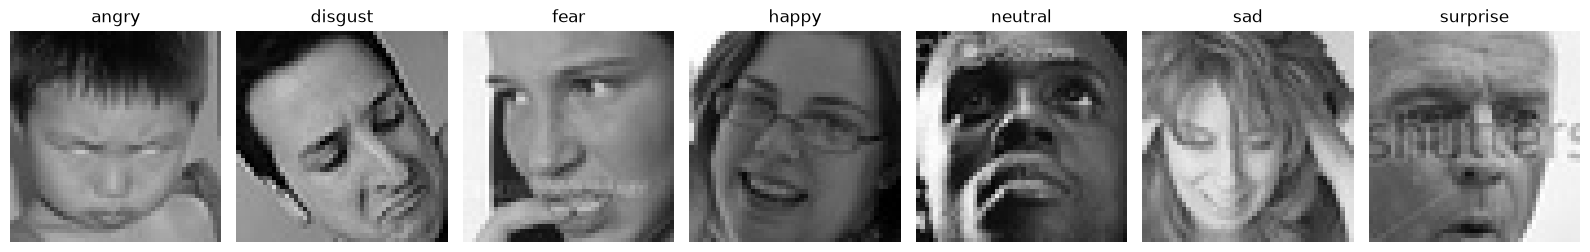

In [34]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 7, figsize=(16, 4))

emotions = [
    "angry", "disgust", "fear", "happy",
    "neutral", "sad", "surprise"
]

for ax, emotion in zip(axes, emotions):
    folder = DATASET_DIR / "train" / emotion
    images = sorted(
        p for p in folder.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    )

    if images:
        with Image.open(images[0]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(emotion)
    else:
        ax.set_title(f"{emotion}\nNo images")

    ax.axis("off")

plt.tight_layout()
plt.show()

## 7. Define normalized geometric feature extraction

To remove variations in face scale, position, and head tilt, the raw 68 landmark coordinates are first normalized using translation, rotation, and inter-ocular scaling. 

The normalized coordinates are then converted into an expanded set of 25 geometric features. These measurements are categorized by anatomical regions (upper face, mid-face, lower face, and symmetry) to support the required ablation studies.

In [35]:
import numpy as np
import math

def normalize_landmarks(points):
    """
    Normalizes 68 facial landmarks based on eye centers.
    Applies translation, rotation, and scaling.
    """
    left_eye_pts = points[36:42]
    right_eye_pts = points[42:48]
    
    left_eye_center = left_eye_pts.mean(axis=0)
    right_eye_center = right_eye_pts.mean(axis=0)
    
    eyes_midpoint = (left_eye_center + right_eye_center) / 2.0
    translated_points = points - eyes_midpoint
    
    dy = right_eye_center[1] - left_eye_center[1]
    dx = right_eye_center[0] - left_eye_center[0]
    angle = np.arctan2(dy, dx)
    
    cos_a = np.cos(-angle)
    sin_a = np.sin(-angle)
    R = np.array([[cos_a, -sin_a], [sin_a, cos_a]])
    rotated_points = np.dot(translated_points, R.T)
    
    new_left_center = np.dot(left_eye_center - eyes_midpoint, R.T)
    new_right_center = np.dot(right_eye_center - eyes_midpoint, R.T)
    inter_ocular_dist = np.linalg.norm(new_right_center - new_left_center)
    
    if inter_ocular_dist < 1e-6:
        return None
        
    return rotated_points / inter_ocular_dist

def calculate_geometric_features(shape):
    """
    Extracts an expanded set of interpretable geometric features 
    from a dlib shape object.
    """
    points = np.array([[shape.part(i).x, shape.part(i).y] for i in range(68)], dtype=float)
    
    norm_points = normalize_landmarks(points)
    if norm_points is None:
        return None
        
    def dist(p1, p2):
        return np.linalg.norm(norm_points[p1] - norm_points[p2])
        
    def aspect_ratio(pts):
        v1 = dist(pts[1], pts[5])
        v2 = dist(pts[2], pts[4])
        h = dist(pts[0], pts[3])
        return (v1 + v2) / (2.0 * h) if h > 0 else 0

    features = {}
    
    features['left_eye_ar'] = aspect_ratio([36, 37, 38, 39, 40, 41])
    features['right_eye_ar'] = aspect_ratio([42, 43, 44, 45, 46, 47])
    features['eye_ar_asymmetry'] = abs(features['left_eye_ar'] - features['right_eye_ar'])
    
    features['left_inner_brow_eye'] = dist(21, 39)
    features['right_inner_brow_eye'] = dist(22, 42)
    features['left_outer_brow_eye'] = dist(17, 36)
    features['right_outer_brow_eye'] = dist(26, 45)
    
    features['left_brow_slope'] = norm_points[21][1] - norm_points[17][1]
    features['right_brow_slope'] = norm_points[22][1] - norm_points[26][1]
    
    features['nose_width'] = dist(31, 35)
    features['nose_bridge_length'] = dist(27, 30)
    features['nose_mouth_dist'] = dist(33, 51)
    
    features['mouth_width'] = dist(48, 54)
    features['mouth_opening'] = dist(51, 57)
    features['mouth_ar'] = features['mouth_opening'] / features['mouth_width'] if features['mouth_width'] > 0 else 0
    features['upper_lip_thickness'] = dist(51, 62)
    features['lower_lip_thickness'] = dist(57, 66)
    
    mouth_center = norm_points[48:60].mean(axis=0)
    features['left_lip_corner_y'] = norm_points[48][1] - mouth_center[1]
    features['right_lip_corner_y'] = norm_points[54][1] - mouth_center[1]
    
    features['jaw_width'] = dist(3, 13)
    features['lower_jaw_width'] = dist(5, 11)
    features['chin_mouth_dist'] = dist(8, 57) 
    features['lower_face_height'] = dist(33, 8) 
    
    features['mouth_asymmetry'] = abs(dist(48, 51) - dist(54, 51))
    features['jaw_asymmetry'] = abs(dist(3, 8) - dist(13, 8))
    
    return features

print("Geometric feature function is ready.")

Geometric feature function is ready.


## 8. Extract features from the training set

This cell processes the FER-2013 training images and writes the extracted features to `dlib_geometry_train.csv`. Processing is performed in batches. If execution is interrupted, image paths already present in the CSV are skipped, allowing the extraction process to resume.

In [36]:
from pathlib import Path
import pandas as pd
import numpy as np
import cv2

train_dir = DATASET_DIR / "train"

PROCESSED_DIR = Path.cwd() / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

output_csv = PROCESSED_DIR / "dlib_geometry_train.csv"

emotion_names = [
    "angry", "disgust", "fear", "happy",
    "neutral", "sad", "surprise"
]

batch_size = 500
batch = []
new_success = 0
new_failed = 0
new_processed = 0

# Read the results already saved
if output_csv.exists():
    existing_df = pd.read_csv(output_csv)
    completed_images = set(existing_df["image"].dropna().astype(str))
    print("Previously saved rows:", len(existing_df))
else:
    existing_df = None
    completed_images = set()

# Build the list of images
image_paths = []

for emotion in emotion_names:
    folder = train_dir / emotion
    for path in sorted(folder.iterdir()):
        if path.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:
            relative_path = str(path.relative_to(DATASET_DIR))
            if relative_path not in completed_images:
                image_paths.append((path, emotion))

print("Images remaining:", len(image_paths))

def save_resume_batch(rows):
    if rows:
        pd.DataFrame(rows).to_csv(
            output_csv,
            mode="a",
            header=not output_csv.exists(),
            index=False
        )

for image_path, emotion in image_paths:
    gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    row = {
        "image": str(image_path.relative_to(DATASET_DIR)),
        "emotion": emotion,
        "landmarks_extracted": False
    }

    if gray is not None:
        faces = face_detector(gray, 2)
        image_for_predictor = gray

        if len(faces) == 0:
            enlarged = cv2.resize(
                gray, None, fx=3, fy=3,
                interpolation=cv2.INTER_CUBIC
            )
            faces = face_detector(enlarged, 2)
            image_for_predictor = enlarged

        if len(faces) > 0:
            shape = landmark_predictor(
                image_for_predictor, faces[0]
            )
            features = calculate_geometric_features(shape)

            if (
                features is not None
                and np.isfinite(list(features.values())).all()
            ):
                row.update(features)
                row["landmarks_extracted"] = True
                new_success += 1
            else:
                new_failed += 1
        else:
            new_failed += 1
    else:
        new_failed += 1

    batch.append(row)
    new_processed += 1

    if len(batch) >= batch_size:
        save_resume_batch(batch)
        batch = []

    if new_processed % 500 == 0:
        print(
            f"New images processed: {new_processed}/"
            f"{len(image_paths)} | "
            f"Successful: {new_success} | Failed: {new_failed}"
        )

save_resume_batch(batch)

# Report totals across all saved batches
final_df = pd.read_csv(output_csv)
successful_total = int(
    (final_df["landmarks_extracted"] == True).sum()
)

print("\nExtraction complete or resumed run finished.")
print("Total saved rows:", len(final_df))
print("Total successful extractions:", successful_total)
print("Total failed extractions:", len(final_df) - successful_total)
print("Overall success rate:",
      f"{successful_total / len(final_df):.2%}")
print("CSV saved to:", output_csv)

Previously saved rows: 28709
Images remaining: 0

Extraction complete or resumed run finished.
Total saved rows: 28709
Total successful extractions: 21464
Total failed extractions: 7245
Overall success rate: 74.76%
CSV saved to: c:\Users\HP\Documents\MiniProject\data\processed\dlib_geometry_train.csv


## 9. Verify the training feature dataset

The generated training CSV is loaded and checked for row count, unique image paths, extraction success, and emotion distribution. Only rows with successful landmark extraction are suitable for classifier training.

In [37]:
train_features_df = pd.read_csv(
    Path.cwd() / "data" / "processed" / "dlib_geometry_train.csv"
)

print("Total CSV rows:", len(train_features_df))
print("Unique image paths:", train_features_df["image"].nunique())
print("\nExtraction status:")
print(train_features_df["landmarks_extracted"].value_counts())
print("\nEmotion distribution:")
print(train_features_df["emotion"].value_counts())

Total CSV rows: 28709
Unique image paths: 28709

Extraction status:
landmarks_extracted
True     21464
False     7245
Name: count, dtype: int64

Emotion distribution:
emotion
happy       7215
neutral     4965
sad         4830
fear        4097
angry       3995
surprise    3171
disgust      436
Name: count, dtype: int64


### Development diagnostic: manifest and feature-path comparison (optional)

This temporary diagnostic compares a few image paths in the shared manifest and extracted feature table. It is not part of model training or evaluation and can be skipped during a clean end-to-end run.

In [38]:

print("MANIFEST IMAGE PATHS:")
print(geometry_manifest["image"].head(5).to_list())

print("\nFEATURE CSV IMAGE PATHS:")
print(train_features_df["image"].head(5).to_list())

print("\nPATH TYPES:")
print("Manifest:", geometry_manifest["image"].dtype)
print("Features:", train_features_df["image"].dtype)

print("\nSAMPLE PATH COMPARISON:")
print("Manifest first path:", repr(geometry_manifest["image"].iloc[0]))
print("Feature first path:", repr(train_features_df["image"].iloc[0]))


MANIFEST IMAGE PATHS:
['train/angry/Training_10118481.jpg', 'train/angry/Training_10120469.jpg', 'train/angry/Training_10131352.jpg', 'train/angry/Training_10161559.jpg', 'train/angry/Training_1021836.jpg']

FEATURE CSV IMAGE PATHS:
['train\\angry\\Training_10118481.jpg', 'train\\angry\\Training_10120469.jpg', 'train\\angry\\Training_10131352.jpg', 'train\\angry\\Training_10161559.jpg', 'train\\angry\\Training_1021836.jpg']

PATH TYPES:
Manifest: str
Features: str

SAMPLE PATH COMPARISON:
Manifest first path: 'train/angry/Training_10118481.jpg'
Feature first path: 'train\\angry\\Training_10118481.jpg'


## 10. Train and validate baseline geometry classifiers

Successfully extracted training examples are divided into stratified training and validation subsets. To prevent data leakage, features are standardized using a scaler fitted exclusively on the training data. We then train and compare three baseline models required by the experimental protocol: a Linear SVM, an RBF SVM, and a class-balanced Random Forest. Validation accuracy and Macro F1 score (the primary project metric) are used to select the best-performing model.

In [39]:

import time
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# --------------------------------------------------
# 1. Attach the fixed manifest partitions
# --------------------------------------------------


# Standardize image paths before merging
partition_info = geometry_manifest[["image", "partition"]].copy()

partition_info["image"] = (
    partition_info["image"].astype(str).str.replace("\\", "/", regex=False)
)

train_features_df["image"] = (
    train_features_df["image"].astype(str).str.replace("\\", "/", regex=False)
)

train_data = train_features_df.merge(
    partition_info,
    on="image",
    how="left",
    validate="one_to_one"
)


# Verify every feature row has a partition
missing_partitions = train_data["partition"].isna().sum()

if missing_partitions > 0:
    raise ValueError(
        f"{missing_partitions} feature rows could not be matched "
        "with the shared manifest. Check image paths."
    )

# --------------------------------------------------
# 2. Keep successfully extracted landmarks
# --------------------------------------------------

train_successful = train_data[
    train_data["landmarks_extracted"] == True
].copy()

# Use only the manifest's fixed train and validation partitions
train_partition = train_successful[
    train_successful["partition"] == "train"
].copy()

validation_partition = train_successful[
    train_successful["partition"] == "validation"
].copy()

# --------------------------------------------------
# 3. Prepare features and labels
# --------------------------------------------------

metadata_columns = [
    "image",
    "emotion",
    "landmarks_extracted",
    "partition",
    "source_split",
    "sample_id",
    "landmark_status",
    "exclusion_reason"
]

feature_columns = [
    col for col in train_successful.columns
    if col not in metadata_columns
]

X_train = train_partition[feature_columns]
y_train = train_partition["emotion"]

X_val = validation_partition[feature_columns]
y_val = validation_partition["emotion"]

# Check for invalid feature values
if not np.isfinite(X_train.to_numpy(dtype=float)).all():
    raise ValueError("Training features contain NaN or infinite values.")

if not np.isfinite(X_val.to_numpy(dtype=float)).all():
    raise ValueError("Validation features contain NaN or infinite values.")

print("FIXED MANIFEST SPLIT")
print("--------------------")
print(f"Training examples:   {len(X_train)}")
print(f"Validation examples: {len(X_val)}")
print(f"Number of features:  {len(feature_columns)}")

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nValidation class distribution:")
print(y_val.value_counts().sort_index())

# --------------------------------------------------
# 4. Standardize features
# Fit scaler ONLY on training data
# --------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# --------------------------------------------------
# 5. Linear SVM
# --------------------------------------------------

print("\n--- Training Linear SVM ---")

linear_svm = SVC(
    kernel="linear",
    class_weight="balanced",
    random_state=42
)

start_time = time.perf_counter()

linear_svm.fit(X_train_scaled, y_train)

linear_svm_training_time = time.perf_counter() - start_time
print(f"Training time: {linear_svm_training_time:.2f} seconds")

y_pred_lin = linear_svm.predict(X_val_scaled)

print(f"Accuracy: {accuracy_score(y_val, y_pred_lin):.2%}")
print(f"Macro F1: {f1_score(y_val, y_pred_lin, average='macro'):.4f}")

# --------------------------------------------------
# 6. RBF SVM
# --------------------------------------------------

print("\n--- Training RBF SVM ---")

rbf_svm = SVC(
    kernel="rbf",
    class_weight="balanced",
    random_state=42
)

start_time = time.perf_counter()

rbf_svm.fit(X_train_scaled, y_train)

rbf_svm_training_time = time.perf_counter() - start_time
print(f"Training time: {rbf_svm_training_time:.2f} seconds")

y_pred_rbf = rbf_svm.predict(X_val_scaled)

print(f"Accuracy: {accuracy_score(y_val, y_pred_rbf):.2%}")
print(f"Macro F1: {f1_score(y_val, y_pred_rbf, average='macro'):.4f}")

# --------------------------------------------------
# 7. Random Forest
# --------------------------------------------------

print("\n--- Training Random Forest ---")

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_time = time.perf_counter()

rf_model.fit(X_train_scaled, y_train)

rf_model_training_time = time.perf_counter() - start_time
print(f"Training time: {rf_model_training_time:.2f} seconds")

y_pred_rf = rf_model.predict(X_val_scaled)

print(f"Accuracy: {accuracy_score(y_val, y_pred_rf):.2%}")
print(f"Macro F1: {f1_score(y_val, y_pred_rf, average='macro'):.4f}")

training_times = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM", "Random Forest"],
    "Training_Time_Seconds": [
        linear_svm_training_time,
        rbf_svm_training_time,
        rf_model_training_time
    ]
})

print("\nTRAINING TIME COMPARISON")
print(training_times)

EXPERIMENTS_DIR = Path.cwd() / "results" / "experiments"
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

training_times.to_csv(
    EXPERIMENTS_DIR / "geometry_training_times.csv",
    index=False
)

FIXED MANIFEST SPLIT
--------------------
Training examples:   17191
Validation examples: 4273
Number of features:  25

Training class distribution:
emotion
angry       2368
disgust      294
fear        2232
happy       4729
neutral     3144
sad         2411
surprise    2013
Name: count, dtype: int64

Validation class distribution:
emotion
angry        596
disgust       64
fear         544
happy       1196
neutral      793
sad          577
surprise     503
Name: count, dtype: int64

--- Training Linear SVM ---
Training time: 24.13 seconds
Accuracy: 47.58%
Macro F1: 0.3938

--- Training RBF SVM ---
Training time: 9.47 seconds
Accuracy: 51.53%
Macro F1: 0.4407

--- Training Random Forest ---
Training time: 1.94 seconds
Accuracy: 54.81%
Macro F1: 0.4947

TRAINING TIME COMPARISON
           Model  Training_Time_Seconds
0     Linear SVM              24.129553
1        RBF SVM               9.473640
2  Random Forest               1.942336


## 11. Detailed Validation Report for Random Forest

In this section, we examine the validation performance of the selected Random Forest classifier in detail.

The classification report provides the following metrics for each emotion category:

- **Precision:** How many samples predicted as a particular emotion were correctly classified.
- **Recall:** How many actual samples of a particular emotion were correctly identified.
- **F1-score:** The harmonic mean of precision and recall.
- **Support:** The number of actual validation samples belonging to each emotion.

This evaluation helps identify which emotion categories are classified effectively and which categories require further improvement.

The validation report is generated using the validation dataset only. The official test dataset remains untouched until the final evaluation.

In [40]:
# 11. Detailed validation report for Random Forest

print("RANDOM FOREST — VALIDATION CLASSIFICATION REPORT")
print("------------------------------------------------")

print(
    classification_report(
        y_val,
        y_pred_rf,
        labels=[
            "angry", "disgust", "fear", "happy",
            "neutral", "sad", "surprise"
        ],
        zero_division=0
    )
)

RANDOM FOREST — VALIDATION CLASSIFICATION REPORT
------------------------------------------------
              precision    recall  f1-score   support

       angry       0.47      0.42      0.44       596
     disgust       0.78      0.33      0.46        64
        fear       0.43      0.23      0.30       544
       happy       0.78      0.78      0.78      1196
     neutral       0.44      0.60      0.51       793
         sad       0.35      0.33      0.34       577
    surprise       0.57      0.69      0.62       503

    accuracy                           0.55      4273
   macro avg       0.55      0.48      0.49      4273
weighted avg       0.55      0.55      0.54      4273



## 12. Extract normalized features from the official test set

The official FER-2013 test images are processed using the updated 25-feature extraction and normalization procedure. Results are saved to `dlib_geometry_test.csv` in batches, with support for resuming an interrupted run.

In [41]:
from pathlib import Path
import pandas as pd
import numpy as np
import cv2

# Official FER-2013 test folder
test_dir = DATASET_DIR / "test"

PROCESSED_DIR = Path.cwd() / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

test_csv = PROCESSED_DIR / "dlib_geometry_test.csv"

emotion_names = [
    "angry", "disgust", "fear", "happy",
    "neutral", "sad", "surprise"
]

# Find test images and skip any already saved
test_image_paths = []

for emotion in emotion_names:
    folder = test_dir / emotion

    for path in sorted(folder.iterdir()):
        if path.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:
            relative_path = path.relative_to(DATASET_DIR).as_posix()
            test_image_paths.append((path, emotion, relative_path))

if test_csv.exists():
    existing_test_df = pd.read_csv(test_csv)
    
    existing_test_df["image"] = (
        existing_test_df["image"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
    )

    completed_paths = set(
        existing_test_df["image"].dropna()
    )
    print("Previously saved rows:", len(existing_test_df))
else:
    completed_paths = set()

remaining_images = [
    (path, emotion, rel_path)
    for path, emotion, rel_path in test_image_paths
    if rel_path not in completed_paths
]

print("Total test images found:", len(test_image_paths))
print("Images remaining:", len(remaining_images))
print("Output file:", test_csv)

batch = []
batch_size = 250
processed = 0
successful = 0
failed = 0

def save_test_batch(rows):
    if rows:
        pd.DataFrame(rows).to_csv(
            test_csv,
            mode="a",
            header=not test_csv.exists(),
            index=False
        )

for image_path, emotion, relative_path in remaining_images:
    gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    row = {
        "image": relative_path,
        "emotion": emotion,
        "landmarks_extracted": False
    }

    if gray is not None:
        faces = face_detector(gray, 2)
        image_for_predictor = gray

        # Retry using an enlarged image if detection fails
        if len(faces) == 0:
            enlarged = cv2.resize(
                gray,
                None,
                fx=3,
                fy=3,
                interpolation=cv2.INTER_CUBIC
            )
            faces = face_detector(enlarged, 2)
            image_for_predictor = enlarged

        if len(faces) == 1:
            shape = landmark_predictor(
                image_for_predictor,
                faces[0]
            )
            features = calculate_geometric_features(shape)

            if (
                features is not None
                and np.isfinite(list(features.values())).all()
            ):
                row.update(features)
                row["landmarks_extracted"] = True
                successful += 1
            else:
                failed += 1
        else:
            failed += 1
    else:
        failed += 1

    batch.append(row)
    processed += 1

    if len(batch) >= batch_size:
        save_test_batch(batch)
        batch = []

    if processed % 250 == 0:
        print(
            f"Processed this run: {processed}/{len(remaining_images)} | "
            f"Successful: {successful} | Failed: {failed}"
        )

save_test_batch(batch)

# Verify the complete saved test dataset
test_features_df = pd.read_csv(test_csv)

print("\nTest feature extraction finished.")
print("Total saved rows:", len(test_features_df))
print("Unique image paths:", test_features_df["image"].nunique())
print(
    "Successful extractions:",
    int((test_features_df["landmarks_extracted"] == True).sum())
)
print(
    "Failed extractions:",
    int((test_features_df["landmarks_extracted"] == False).sum())
)
print("Saved to:", test_csv)

Previously saved rows: 7178
Total test images found: 7178
Images remaining: 0
Output file: c:\Users\HP\Documents\MiniProject\data\processed\dlib_geometry_test.csv

Test feature extraction finished.
Total saved rows: 7178
Unique image paths: 7178
Successful extractions: 5378
Failed extractions: 1800
Saved to: c:\Users\HP\Documents\MiniProject\data\processed\dlib_geometry_test.csv


## 13. Evaluate the best baseline on the official FER-2013 test set

The test features are standardized using the exact same scaler fitted on the training set to prevent data leakage. The top-performing baseline model (Random Forest) predicts labels for test images with successfully extracted landmarks. Test Accuracy, Macro F1, the classification report, and the confusion matrix summarize final standalone geometry performance.

TEST DATA INTEGRATION VERIFIED
--------------------------------
Total official test samples: 7178
Unique image paths: 7178

OFFICIAL TEST SET — EXTRACTION SUMMARY
---------------------------------------
Official test images: 7178
Successful extractions: 5378
Failed extractions: 1800
Extraction coverage: 74.92%

OFFICIAL TEST SET — RANDOM FOREST RESULTS
-----------------------------------------
Test Accuracy:    0.5632
Test Macro F1:    0.5180
Test Weighted F1: 0.5531

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

       angry       0.46      0.47      0.46       721
     disgust       0.76      0.39      0.51        88
        fear       0.47      0.22      0.30       709
       happy       0.78      0.78      0.78      1465
     neutral       0.48      0.62      0.54       983
         sad       0.35      0.35      0.35       762
    surprise       0.64      0.74      0.68       650

    accuracy                           0.56      

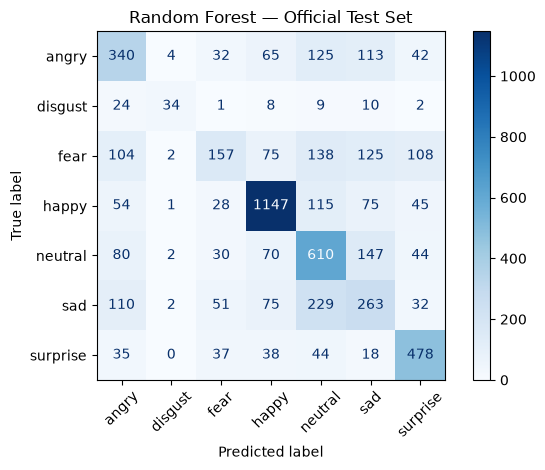

In [42]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. NORMALIZE IMAGE PATHS
# --------------------------------------------------

test_features_df["image"] = (
    test_features_df["image"]
    .astype(str)
    .str.replace("\\", "/", regex=False)
)

# --------------------------------------------------
# 2. SELECT OFFICIAL TEST SAMPLES FROM MANIFEST
# --------------------------------------------------

official_test_manifest = geometry_manifest[
    geometry_manifest["partition"] == "test"
].copy()

# Keep only necessary manifest columns.
# This avoids duplicate landmarks_extracted columns.
official_test_manifest = official_test_manifest[
    ["image", "emotion", "partition"]
]

# --------------------------------------------------
# 3. INTEGRATE TEST FEATURES WITH MANIFEST
# --------------------------------------------------

test_evaluation_df = official_test_manifest.merge(
    test_features_df,
    on=["image", "emotion"],
    how="left",
    validate="one_to_one"
)

# --------------------------------------------------
# 4. VERIFY DATA INTEGRITY
# --------------------------------------------------

assert len(test_evaluation_df) == 7178, \
    "Official test sample count mismatch!"

assert test_evaluation_df["landmarks_extracted"].notna().all(), \
    "Some test samples are missing extraction records!"

assert test_evaluation_df["image"].nunique() == 7178, \
    "Duplicate or missing test image paths detected!"

print("TEST DATA INTEGRATION VERIFIED")
print("--------------------------------")
print("Total official test samples:", len(test_evaluation_df))
print("Unique image paths:", test_evaluation_df["image"].nunique())

# --------------------------------------------------
# 5. SELECT SUCCESSFULLY EXTRACTED SAMPLES
# --------------------------------------------------

test_successful = test_evaluation_df[
    test_evaluation_df["landmarks_extracted"] == True
].copy()

X_test = test_successful[feature_columns]
y_test = test_successful["emotion"]

# --------------------------------------------------
# 6. SCALE TEST FEATURES
# --------------------------------------------------

# IMPORTANT: Use the scaler fitted on training data.
# Do not fit or refit the scaler on test data.

X_test_scaled = scaler.transform(X_test)

# --------------------------------------------------
# 7. RANDOM FOREST PREDICTION
# --------------------------------------------------

y_test_pred = rf_model.predict(X_test_scaled)

# --------------------------------------------------
# 8. TEST SET COVERAGE
# --------------------------------------------------

total_test_images = len(test_evaluation_df)
successful_extractions = len(test_successful)
failed_extractions = total_test_images - successful_extractions

print("\nOFFICIAL TEST SET — EXTRACTION SUMMARY")
print("---------------------------------------")
print("Official test images:", total_test_images)
print("Successful extractions:", successful_extractions)
print("Failed extractions:", failed_extractions)

print(
    "Extraction coverage:",
    f"{successful_extractions / total_test_images:.2%}"
)

# --------------------------------------------------
# 9. CLASSIFICATION METRICS
# --------------------------------------------------

test_accuracy = accuracy_score(y_test, y_test_pred)

test_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro"
)

test_weighted_f1 = f1_score(
    y_test,
    y_test_pred,
    average="weighted"
)

print("\nOFFICIAL TEST SET — RANDOM FOREST RESULTS")
print("-----------------------------------------")
print(f"Test Accuracy:    {test_accuracy:.4f}")
print(f"Test Macro F1:    {test_macro_f1:.4f}")
print(f"Test Weighted F1: {test_weighted_f1:.4f}")

# --------------------------------------------------
# 10. CLASSIFICATION REPORT
# --------------------------------------------------

print("\nCLASSIFICATION REPORT")
print("---------------------")

print(
    classification_report(
        y_test,
        y_test_pred,
        labels=rf_model.classes_,
        zero_division=0
    )
)

# --------------------------------------------------
# 11. CONFUSION MATRIX
# --------------------------------------------------

cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels=rf_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=rf_model.classes_
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Random Forest — Official Test Set")
plt.tight_layout()
plt.show()

## 14. Anatomical Region Ablation Study

To understand which facial regions contribute most to emotion recognition, geometric features are isolated into Upper Face (eyes/brows), Mid Face (nose), and Lower Face (mouth/jaw). A Random Forest is trained on each subset to compare regional predictive power against the combined full-feature model.

In [43]:
upper_features = [
    col for col in feature_columns
    if "eye" in col.lower() or "brow" in col.lower()
]

mid_features = [
    col for col in feature_columns
    if "nose" in col.lower()
]

lower_features = [
    col for col in feature_columns
    if any(name in col.lower() for name in ["mouth", "lip", "jaw", "chin", "lower_face"])
]

regions = {
    "Upper Face (Eyes & Brows)": upper_features,
    "Mid Face (Nose)": mid_features,
    "Lower Face (Mouth & Jaw)": lower_features,
    "All Regions (Combined)": feature_columns
}

# Check feature grouping
assigned_features = set(
    upper_features + mid_features + lower_features
)

unassigned_features = [
    col for col in feature_columns
    if col not in assigned_features
]

print("Feature counts:")
for region_name, region_cols in regions.items():
    print(f"{region_name}: {len(region_cols)}")

print("\nUnassigned features:", unassigned_features)

# Run anatomical ablation study
ablation_results = []

print("\nAnatomical Ablation Study Results (Validation Set)\n")

for region_name, region_cols in regions.items():

    if len(region_cols) == 0:
        print(f"Skipping {region_name}: no features found.")
        continue

    col_indices = [
        feature_columns.index(col)
        for col in region_cols
    ]

    X_train_region = X_train_scaled[:, col_indices]
    X_val_region = X_val_scaled[:, col_indices]

    model = RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_region, y_train)

    preds = model.predict(X_val_region)

    acc = accuracy_score(y_val, preds)
    macro_f1 = f1_score(y_val, preds, average="macro")

    ablation_results.append({
        "Region": region_name,
        "Features": len(region_cols),
        "Accuracy": acc,
        "Macro F1": macro_f1
    })

# Display ablation results
ablation_df = (
    pd.DataFrame(ablation_results)
    .sort_values(by="Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(ablation_df)

Feature counts:
Upper Face (Eyes & Brows): 9
Mid Face (Nose): 3
Lower Face (Mouth & Jaw): 14
All Regions (Combined): 25

Unassigned features: []

Anatomical Ablation Study Results (Validation Set)



,Region,Features,Accuracy,Macro F1
0,All Regions (Combined),25,0.548093,0.494651
1,Lower Face (Mouth & Jaw),14,0.508074,0.449692
2,Upper Face (Eyes & Brows),9,0.362275,0.348474
3,Mid Face (Nose),3,0.348233,0.315391


## 15. Save the trained geometry model and scaler

The fitted Random Forest model, the standard scaler, the feature-column order, and the emotion classes are saved to disk. Retaining the scaler and feature order ensures that future prediction inputs from the fusion module are perfectly aligned and standardized.

In [44]:
import joblib
from pathlib import Path

output_dir = Path.cwd() / "models"
output_dir.mkdir(parents=True, exist_ok=True)

model_artifact = {
    "model": rf_model,
    "scaler": scaler,
    "feature_columns": feature_columns,
    "emotion_classes": list(rf_model.classes_),
    "model_name": "Random Forest",
    "n_features": len(feature_columns),
    "random_state": 42
}

joblib.dump(
    model_artifact,
    output_dir / "dlib_geometry_model_expanded.joblib"
)

print("Expanded geometry model and scaler saved successfully.")
print("Model file:", output_dir / "dlib_geometry_model_expanded.joblib")

Expanded geometry model and scaler saved successfully.
Model file: c:\Users\HP\Documents\MiniProject\models\dlib_geometry_model_expanded.joblib


### 15A. Saves the Random Forest’s class probabilities for every validation and test image, with geometry_available = False where no landmarks were found. These files are used for score-level fusion with the appearance branch.

In [45]:
def export_probabilities(features_df, partition_name, out_csv):
    d = features_df.copy()
    d["image"] = d["image"].astype(str).str.replace("\\", "/", regex=False)
    d = d.merge(geometry_manifest[["image", "partition"]], on="image", how="inner", validate="one_to_one")
    d = d[d["partition"] == partition_name].reset_index(drop=True)
    ok = d["landmarks_extracted"].to_numpy(bool)
    probs = np.full((len(d), len(rf_model.classes_)), np.nan)
    if ok.any():
        probs[ok] = rf_model.predict_proba(scaler.transform(d.loc[ok, feature_columns]))
    out = d[["image", "emotion", "partition"]].copy()
    out["geometry_available"] = ok
    for j, c in enumerate(rf_model.classes_):
        out[f"p_{c}"] = probs[:, j]
    out.to_csv(out_csv, index=False)
    return out

PREDICTIONS_DIR = Path.cwd() / "results" / "predictions"
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)

geo_val = export_probabilities(
    train_features_df,
    "validation",
    PREDICTIONS_DIR / "geometry_predictions_validation.csv"
)

geo_test = export_probabilities(
    test_features_df,
    "test",
    PREDICTIONS_DIR / "geometry_predictions_test.csv"
)

print("Validation file:", geo_val.shape, "| rows with probabilities:", int(geo_val["geometry_available"].sum()))
print("Test file      :", geo_test.shape, "| rows with probabilities:", int(geo_test["geometry_available"].sum()))
display(geo_val.head())

Validation file: (5742, 11) | rows with probabilities: 4273
Test file      : (7178, 11) | rows with probabilities: 5378


,image,emotion,partition,geometry_available,p_angry,p_disgust,p_fear,p_happy,p_neutral,p_sad,p_surprise
0,train/angry/Training_10120469.jpg,angry,validation,True,0.190,0.015,0.105,0.150,0.300,0.215,0.025
1,train/angry/Training_1021836.jpg,angry,validation,True,0.235,0.050,0.210,0.105,0.070,0.165,0.165
2,train/angry/Training_10333072.jpg,angry,validation,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,train/angry/Training_10503476.jpg,angry,validation,True,0.305,0.155,0.070,0.080,0.125,0.230,0.035
4,train/angry/Training_10592361.jpg,angry,validation,True,0.480,0.005,0.265,0.060,0.035,0.025,0.130


## 16. Dataset Schema and Integrity Audit

This section dynamically audits the final generated CSV files to confirm the dataset dimensions, data types, and schema. It ensures that the 25 expanded geometric features and 3 metadata columns are correctly formatted for reproducibility.

In [46]:
from pathlib import Path
import pandas as pd

# Locate the existing feature files

PROCESSED_DIR = Path.cwd() / "data" / "processed"
train_csv = PROCESSED_DIR / "dlib_geometry_train.csv"
test_csv = PROCESSED_DIR / "dlib_geometry_test.csv"

# Load the existing results
train_df = pd.read_csv(train_csv)
test_df = pd.read_csv(test_csv)

# Inspect the training dataset
print("TRAINING CSV")
print("Shape:", train_df.shape)
print("Columns:", train_df.columns.tolist())
print("\nData types:")
print(train_df.dtypes)
print("\nFirst 5 rows:")
display(train_df.head())

print("\n" + "=" * 60)

# Inspect the test dataset
print("TEST CSV")
print("Shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())
print("\nData types:")
print(test_df.dtypes)
print("\nFirst 5 rows:")
display(test_df.head())

print("\n" + "=" * 60)

# Check dataset integrity
print("DATASET INTEGRITY CHECK")

for name, df in [("Training", train_df), ("Test", test_df)]:
    print(f"\n{name} Dataset")
    print("Total rows:", len(df))
    print("Unique image paths:", df["image"].nunique())
    print("Duplicate image paths:", df["image"].duplicated().sum())
    print("Missing image paths:", df["image"].isna().sum())
    print("Missing emotion labels:", df["emotion"].isna().sum())
    print("Missing extraction statuses:", df["landmarks_extracted"].isna().sum())
    print(
        "Successful extractions:",
        int((df["landmarks_extracted"] == True).sum())
    )
    print(
        "Failed extractions:",
        int((df["landmarks_extracted"] == False).sum())
    )

# Check the expected feature columns
metadata_columns = ["image", "emotion", "landmarks_extracted"]

actual_feature_columns = [
    col for col in train_df.columns
    if col not in metadata_columns
]

print("\nExpected feature count:", len(feature_columns))
print("Training feature count:", len(actual_feature_columns))
print("Feature columns match:", actual_feature_columns == feature_columns)
print(
    "Test feature columns match:",
    [col for col in test_df.columns if col not in metadata_columns]
    == feature_columns
)

TRAINING CSV
Shape: (28709, 28)
Columns: ['image', 'emotion', 'landmarks_extracted', 'left_eye_ar', 'right_eye_ar', 'eye_ar_asymmetry', 'left_inner_brow_eye', 'right_inner_brow_eye', 'left_outer_brow_eye', 'right_outer_brow_eye', 'left_brow_slope', 'right_brow_slope', 'nose_width', 'nose_bridge_length', 'nose_mouth_dist', 'mouth_width', 'mouth_opening', 'mouth_ar', 'upper_lip_thickness', 'lower_lip_thickness', 'left_lip_corner_y', 'right_lip_corner_y', 'jaw_width', 'lower_jaw_width', 'chin_mouth_dist', 'lower_face_height', 'mouth_asymmetry', 'jaw_asymmetry']

Data types:
image                       str
emotion                     str
landmarks_extracted        bool
left_eye_ar             float64
right_eye_ar            float64
eye_ar_asymmetry        float64
left_inner_brow_eye     float64
right_inner_brow_eye    float64
left_outer_brow_eye     float64
right_outer_brow_eye    float64
left_brow_slope         float64
right_brow_slope        float64
nose_width              float64
nose_b

,image,emotion,landmarks_extracted,left_eye_ar,right_eye_ar,eye_ar_asymmetry,left_inner_brow_eye,right_inner_brow_eye,left_outer_brow_eye,right_outer_brow_eye,...,upper_lip_thickness,lower_lip_thickness,left_lip_corner_y,right_lip_corner_y,jaw_width,lower_jaw_width,chin_mouth_dist,lower_face_height,mouth_asymmetry,jaw_asymmetry
0,train\angry\Training_10118481.jpg,angry,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,train\angry\Training_10120469.jpg,angry,True,0.300461,0.415381,0.114919,0.441480,0.227140,0.272988,0.272988,...,0.075713,0.107075,-0.044586,-0.042675,2.066567,1.531204,0.646894,1.054562,0.223200,0.257256
2,train\angry\Training_10131352.jpg,angry,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,train\angry\Training_10161559.jpg,angry,True,0.378431,0.404522,0.026091,0.484901,0.382686,0.366452,0.382686,...,0.142372,0.151008,0.039519,0.042897,2.410248,1.586822,0.665121,1.248495,0.251825,0.347752
4,train\angry\Training_1021836.jpg,angry,True,0.310087,0.299535,0.010552,0.346973,0.370285,0.208505,0.289144,...,0.057829,0.129309,0.009614,0.033581,2.037183,1.464108,0.581172,1.226734,0.011246,0.027893



TEST CSV
Shape: (7178, 28)
Columns: ['image', 'emotion', 'landmarks_extracted', 'left_eye_ar', 'right_eye_ar', 'eye_ar_asymmetry', 'left_inner_brow_eye', 'right_inner_brow_eye', 'left_outer_brow_eye', 'right_outer_brow_eye', 'left_brow_slope', 'right_brow_slope', 'nose_width', 'nose_bridge_length', 'nose_mouth_dist', 'mouth_width', 'mouth_opening', 'mouth_ar', 'upper_lip_thickness', 'lower_lip_thickness', 'left_lip_corner_y', 'right_lip_corner_y', 'jaw_width', 'lower_jaw_width', 'chin_mouth_dist', 'lower_face_height', 'mouth_asymmetry', 'jaw_asymmetry']

Data types:
image                       str
emotion                     str
landmarks_extracted        bool
left_eye_ar             float64
right_eye_ar            float64
eye_ar_asymmetry        float64
left_inner_brow_eye     float64
right_inner_brow_eye    float64
left_outer_brow_eye     float64
right_outer_brow_eye    float64
left_brow_slope         float64
right_brow_slope        float64
nose_width              float64
nose_bridg

,image,emotion,landmarks_extracted,left_eye_ar,right_eye_ar,eye_ar_asymmetry,left_inner_brow_eye,right_inner_brow_eye,left_outer_brow_eye,right_outer_brow_eye,...,upper_lip_thickness,lower_lip_thickness,left_lip_corner_y,right_lip_corner_y,jaw_width,lower_jaw_width,chin_mouth_dist,lower_face_height,mouth_asymmetry,jaw_asymmetry
0,test\angry\PrivateTest_10131363.jpg,angry,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,test\angry\PrivateTest_10304478.jpg,angry,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,test\angry\PrivateTest_1054527.jpg,angry,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,test\angry\PrivateTest_10590091.jpg,angry,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,test\angry\PrivateTest_1109992.jpg,angry,True,0.282843,0.248069,0.034773,0.378947,0.455438,0.368271,0.404408,...,0.063158,0.126316,-0.094737,-0.094737,2.400831,1.515789,0.446594,1.090274,0.315789,0.458943



DATASET INTEGRITY CHECK

Training Dataset
Total rows: 28709
Unique image paths: 28709
Duplicate image paths: 0
Missing image paths: 0
Missing emotion labels: 0
Missing extraction statuses: 0
Successful extractions: 21464
Failed extractions: 7245

Test Dataset
Total rows: 7178
Unique image paths: 7178
Duplicate image paths: 0
Missing image paths: 0
Missing emotion labels: 0
Missing extraction statuses: 0
Successful extractions: 5378
Failed extractions: 1800

Expected feature count: 25
Training feature count: 25
Feature columns match: True
Test feature columns match: True


## 17. Training Set Landmark Coverage Analysis

Landmark detection quality must be treated as data, not hidden preprocessing[cite: 7]. This analysis calculates the successful detection rate across the training set, stratified by emotion class, to identify potential failure biases in minority or challenging categories.

In [47]:
# Calculate landmark detection statistics by emotion

def calculate_coverage(df, dataset_name):
    results = (
        df.groupby("emotion")
        .agg(
            total_images=("landmarks_extracted", "size"),
            successful=("landmarks_extracted", "sum")
        )
        .reset_index()
    )

    results["failed"] = (
        results["total_images"] - results["successful"]
    )

    results["coverage_percent"] = (
        results["successful"] / results["total_images"] * 100
    ).round(2)

    results["failure_percent"] = (
        results["failed"] / results["total_images"] * 100
    ).round(2)

    print(f"\n{dataset_name} LANDMARK COVERAGE")
    display(results)

    return results


# Calculate separately for training and test datasets
train_coverage = calculate_coverage(train_df, "TRAINING")
test_coverage = calculate_coverage(test_df, "TEST")


# Calculate overall coverage
print("\nOVERALL COVERAGE")

for name, df in [
    ("Training", train_df),
    ("Test", test_df)
]:
    total = len(df)
    successful = int(df["landmarks_extracted"].sum())
    failed = total - successful
    coverage = successful / total * 100
    failure = failed / total * 100

    print(
        f"{name}: {successful}/{total} "
        f"({coverage:.2f}% coverage, {failure:.2f}% failure)"
    )


TRAINING LANDMARK COVERAGE


,emotion,total_images,successful,failed,coverage_percent,failure_percent
0,angry,3995,2964,1031,74.19,25.81
1,disgust,436,358,78,82.11,17.89
2,fear,4097,2776,1321,67.76,32.24
3,happy,7215,5925,1290,82.12,17.88
4,neutral,4965,3937,1028,79.30,20.70
5,sad,4830,2988,1842,61.86,38.14
6,surprise,3171,2516,655,79.34,20.66



TEST LANDMARK COVERAGE


,emotion,total_images,successful,failed,coverage_percent,failure_percent
0,angry,958,721,237,75.26,24.74
1,disgust,111,88,23,79.28,20.72
2,fear,1024,709,315,69.24,30.76
3,happy,1774,1465,309,82.58,17.42
4,neutral,1233,983,250,79.72,20.28
5,sad,1247,762,485,61.11,38.89
6,surprise,831,650,181,78.22,21.78



OVERALL COVERAGE
Training: 21464/28709 (74.76% coverage, 25.24% failure)
Test: 5378/7178 (74.92% coverage, 25.08% failure)


## 18. Test Set and Overall Landmark Coverage

This step evaluates the landmark detector's success rate on the official test set and calculates the overall pipeline coverage. Because the classifier can only process images with successfully extracted landmarks, these percentages represent the maximum theoretical availability of the standalone geometry branch.

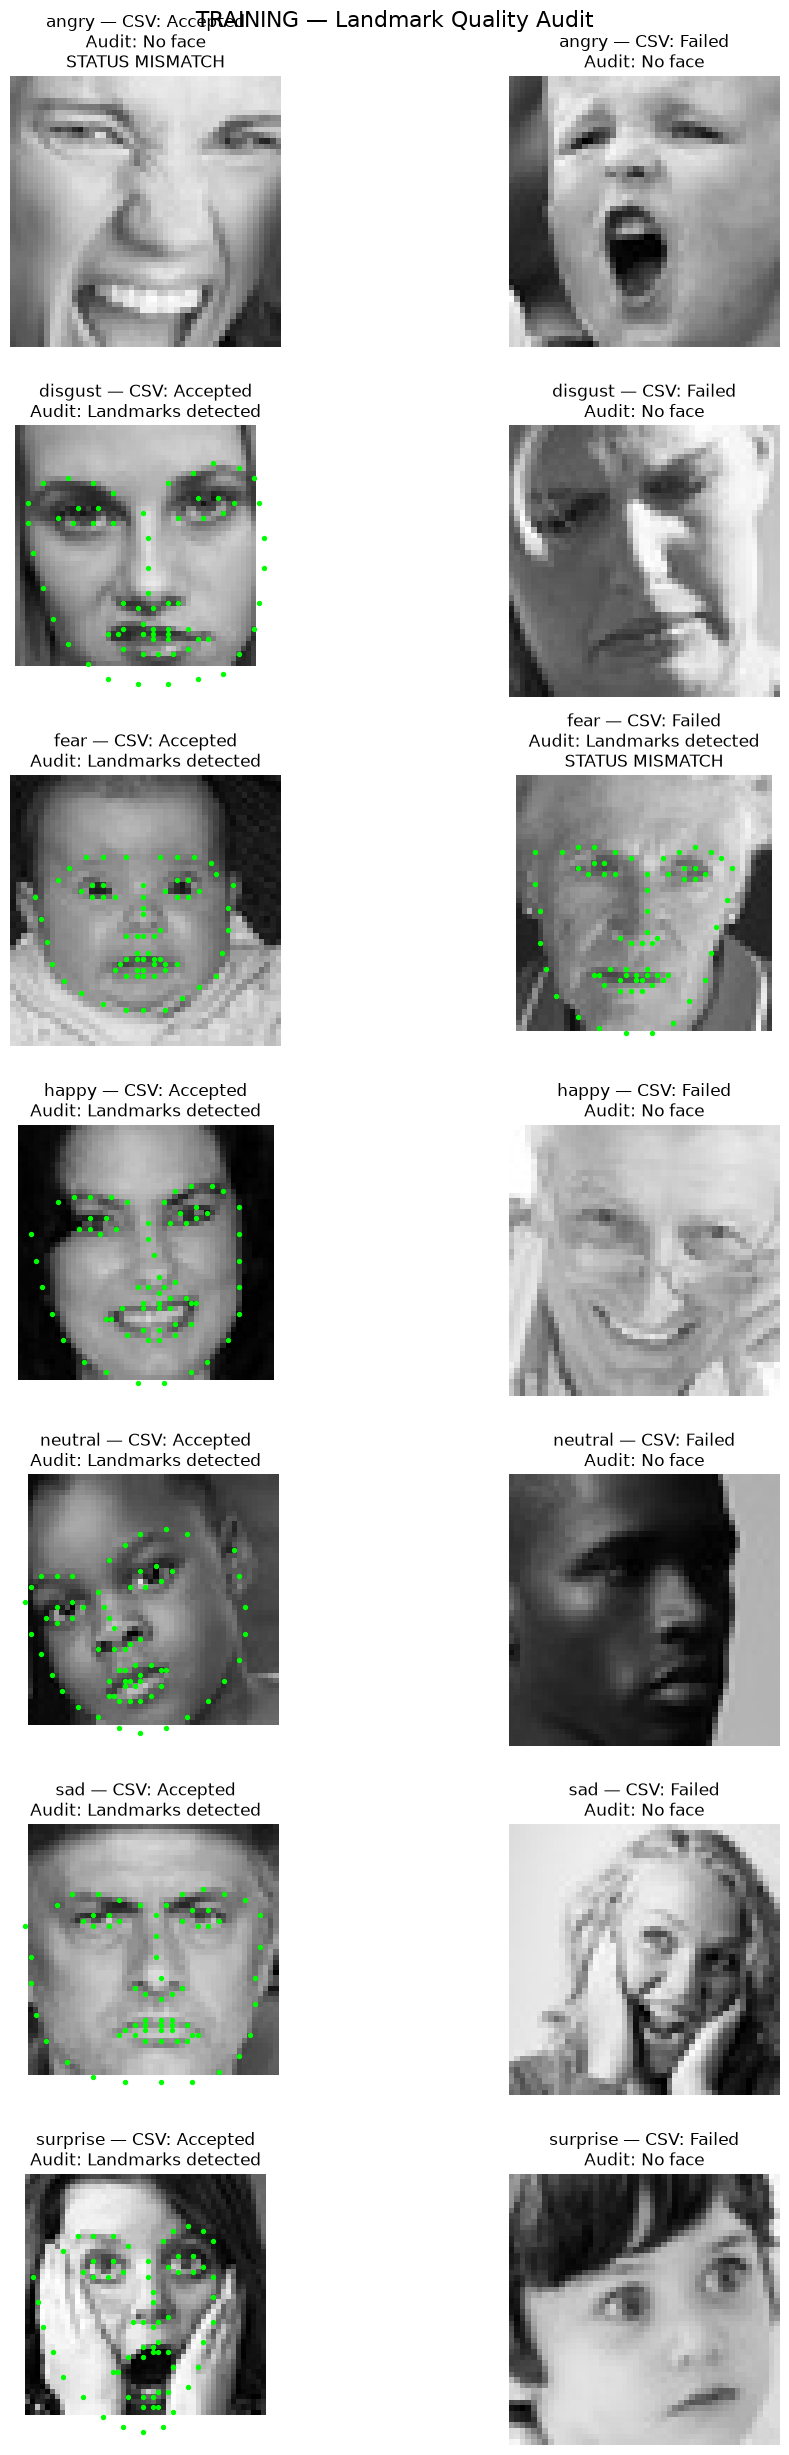

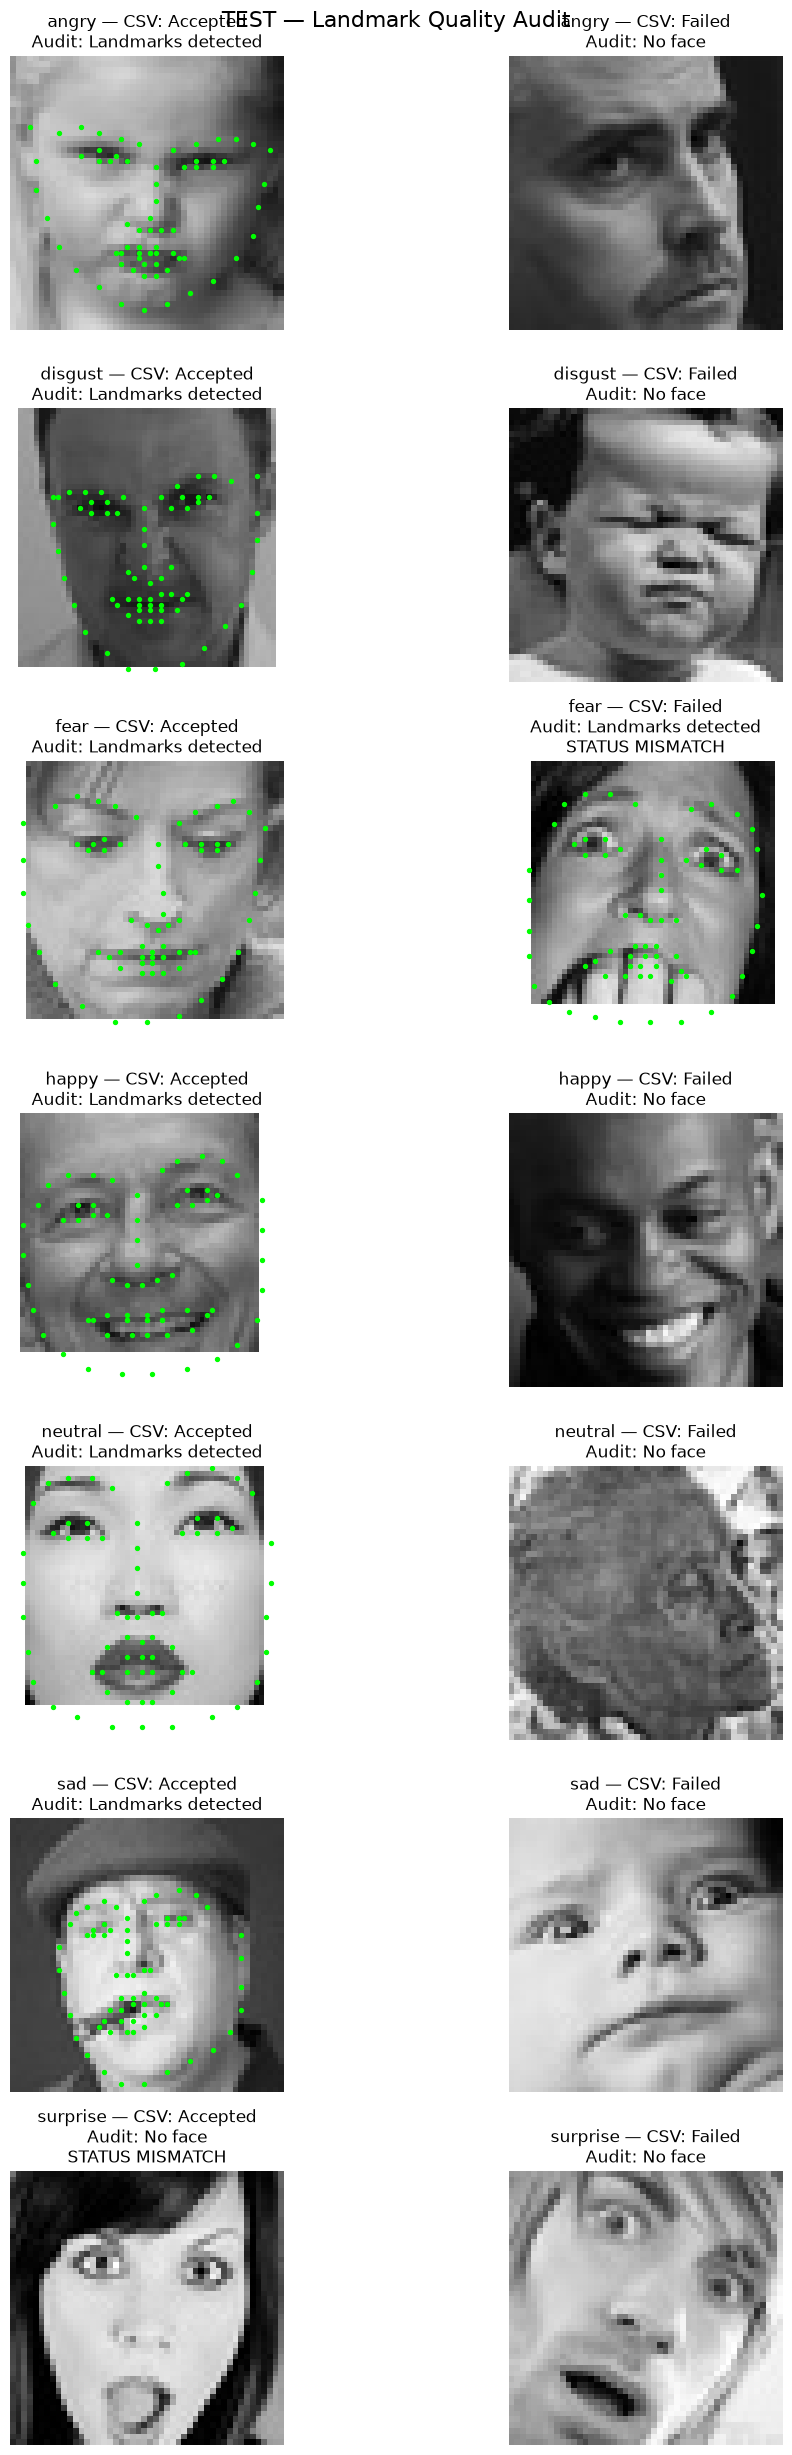

In [48]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Dataset directory
DATASET_DIR = Path.cwd() / "data" / "FER-2013"

emotions = [
    "angry", "disgust", "fear", "happy",
    "neutral", "sad", "surprise"
]


def load_and_detect(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        return None, None, "Unreadable image"

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    faces = face_detector(gray, 2)
    scale = 1

    if len(faces) == 0:
        enlarged = cv2.resize(
            gray, None, fx=3, fy=3,
            interpolation=cv2.INTER_CUBIC
        )
        faces = face_detector(enlarged, 0)
        scale = 3
    else:
        enlarged = None

    if len(faces) == 0:
        return cv2.cvtColor(image, cv2.COLOR_BGR2RGB), None, "No face"

    if len(faces) != 1:
        return cv2.cvtColor(image, cv2.COLOR_BGR2RGB), None, "Multiple faces"

    detection_image = gray if scale == 1 else enlarged

    shape = landmark_predictor(detection_image, faces[0])

    points = np.array([
        [shape.part(i).x / scale, shape.part(i).y / scale]
        for i in range(68)
    ], dtype=int)

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    return rgb, points, "Landmarks detected"


def show_landmark_audit(df, split_name):

    fig, axes = plt.subplots(7, 2, figsize=(12, 25))

    fig.suptitle(
        f"{split_name.upper()} — Landmark Quality Audit",
        fontsize=16
    )

    for i, emotion in enumerate(emotions):

        class_df = df[df["emotion"] == emotion]

        accepted = class_df[class_df["landmarks_extracted"] == True]
        failed = class_df[class_df["landmarks_extracted"] == False]

        samples = []

        if not accepted.empty:
            samples.append((accepted.sample(n=1, random_state=42).iloc[0], "Accepted"))

        if not failed.empty:
            samples.append((failed.sample(n=1, random_state=42).iloc[0], "Failed"))

        for j in range(2):

            ax = axes[i, j]

            if j >= len(samples):
                ax.set_title(f"{emotion} — No sample available")
                ax.axis("off")
                continue

            row, csv_status = samples[j]

            image_path = (
                DATASET_DIR /
                str(row["image"]).replace("\\", "/")
            )

            image, points, actual_status = load_and_detect(image_path)

            if image is None:
                ax.set_title(f"{emotion} — Image unreadable")
                ax.axis("off")
                continue

            ax.imshow(image)

            if points is not None:
                ax.scatter(
                    points[:, 0],
                    points[:, 1],
                    s=8,
                    c="lime"
                )

            mismatch = (
                (csv_status == "Accepted" and points is None)
                or (csv_status == "Failed" and points is not None)
            )

            ax.set_title(
                f"{emotion} — CSV: {csv_status}\n"
                f"Audit: {actual_status}"
                + ("\nSTATUS MISMATCH" if mismatch else "")
            )

            ax.axis("off")

    plt.tight_layout()
    plt.show()


# Audit training and test images separately
show_landmark_audit(train_df, "Training")
show_landmark_audit(test_df, "Test")

## 19. Error Analysis Record Extraction

To satisfy the project's error analysis protocol, we extract a stratified sample of correct and incorrect predictions from our best standalone model. Inspecting these records allows us to distinguish genuine representation failures (where explicit geometry fails to capture the emotion) from dataset noise, label ambiguity, or anomalous landmark detections.

In [49]:
# Add predictions and correctness status
test_successful = test_successful.copy()

test_successful["predicted_emotion"] = y_test_pred
test_successful["is_correct"] = (
    test_successful["emotion"] == test_successful["predicted_emotion"]
)

# Select up to 20 correct and incorrect cases per emotion (when available)
correct_sample = (
    test_successful[test_successful["is_correct"]]
    .groupby("emotion", group_keys=False)
    .head(20)
)

incorrect_sample = (
    test_successful[~test_successful["is_correct"]]
    .groupby("emotion", group_keys=False)
    .head(20)
)

columns_to_display = [
    "image",
    "emotion",
    "predicted_emotion",
    "mouth_ar",
    "left_eye_ar",
    "left_brow_slope"
]

print("CORRECT PREDICTIONS")
print("Number of samples:", len(correct_sample))
print("Target (20):", "met" if len(correct_sample) >= 20 else "not met — fewer correct predictions are available")
display(correct_sample[columns_to_display])

print("\nINCORRECT PREDICTIONS")
print("Number of samples:", len(incorrect_sample))
print("Target (20):", "met" if len(incorrect_sample) >= 20 else "not met — fewer incorrect predictions are available")
display(incorrect_sample[columns_to_display])

CORRECT PREDICTIONS
Number of samples: 140
Target (20): met


,image,emotion,predicted_emotion,mouth_ar,left_eye_ar,left_brow_slope
7,test/angry/PrivateTest_12008383.jpg,angry,angry,0.720764,0.293610,-0.156230
9,test/angry/PrivateTest_1221822.jpg,angry,angry,0.688468,0.415227,0.045713
14,test/angry/PrivateTest_12912780.jpg,angry,angry,0.363290,0.310087,0.134357
16,test/angry/PrivateTest_13278552.jpg,angry,angry,0.752920,0.310988,-0.102368
20,test/angry/PrivateTest_14325168.jpg,angry,angry,0.857143,0.196116,-0.153576
...,...,...,...,...,...,...
6380,test/surprise/PrivateTest_15433995.jpg,surprise,surprise,1.094690,0.428571,-0.235294
6381,test/surprise/PrivateTest_15448000.jpg,surprise,surprise,0.597022,0.496139,-0.133290
6382,test/surprise/PrivateTest_15523257.jpg,surprise,surprise,0.907923,0.428571,0.036393
6385,test/surprise/PrivateTest_15770032.jpg,surprise,surprise,0.692308,0.494975,-0.114610



INCORRECT PREDICTIONS
Number of samples: 140
Target (20): met


,image,emotion,predicted_emotion,mouth_ar,left_eye_ar,left_brow_slope
4,test/angry/PrivateTest_1109992.jpg,angry,sad,0.392232,0.282843,0.000000
5,test/angry/PrivateTest_11296953.jpg,angry,neutral,0.263158,0.222222,0.019037
8,test/angry/PrivateTest_12191716.jpg,angry,neutral,0.465361,0.415227,-0.035710
10,test/angry/PrivateTest_12403575.jpg,angry,happy,0.217006,0.256849,0.130083
11,test/angry/PrivateTest_12766285.jpg,angry,fear,0.379432,0.375000,-0.184173
...,...,...,...,...,...,...
6419,test/surprise/PrivateTest_22866077.jpg,surprise,angry,0.612962,0.250000,-0.021898
6421,test/surprise/PrivateTest_23067313.jpg,surprise,happy,0.449439,0.231148,-0.054960
6426,test/surprise/PrivateTest_23654848.jpg,surprise,angry,0.600000,0.242536,0.057508
6428,test/surprise/PrivateTest_24065334.jpg,surprise,sad,0.505146,0.310087,-0.019005


## 20. Detailed Error Analysis — Prediction Confidence and Emotion Confusion

This section examines the predictions made by the trained Random Forest geometry classifier on the official test dataset.

The analysis focuses on:

1. **Confusion Matrix:** Identifies how frequently each emotion is correctly classified or confused with another emotion.
2. **Emotion Confusion Pairs:** Identifies the most frequent pairs of actual and predicted emotions.
3. **Prediction Confidence:** Examines the confidence scores associated with correct and incorrect predictions.

This analysis helps identify the strengths and weaknesses of the geometric feature representation and understand the classification errors made by the model.

**Note:** Random Forest prediction probabilities represent model confidence estimates and are not necessarily calibrated probabilities. The official test results are used only for evaluation and error analysis, not for model tuning.

In [50]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

# Calculate prediction confidence
test_successful["prediction_confidence"] = (
    rf_model.predict_proba(X_test_scaled).max(axis=1)
)

# Display the confusion matrix
confusion = confusion_matrix(
    test_successful["emotion"],
    test_successful["predicted_emotion"],
    labels=rf_model.classes_
)

confusion_df = pd.DataFrame(
    confusion,
    index=rf_model.classes_,
    columns=rf_model.classes_
)

print("CONFUSION MATRIX")
display(confusion_df)

# Extract incorrect emotion pairs
incorrect_pairs = (
    test_successful[
        test_successful["emotion"] != test_successful["predicted_emotion"]
    ]
    .groupby(["emotion", "predicted_emotion"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

print("\nTOP 10 EMOTION CONFUSIONS")
display(incorrect_pairs.head(10))

# Compare prediction confidence
print("\nAVERAGE PREDICTION CONFIDENCE")

confidence_summary = (
    test_successful.groupby("is_correct")["prediction_confidence"]
    .agg(["count", "mean", "median"])
    .rename(index={
        True: "Correct",
        False: "Incorrect"
    })
)

display(confidence_summary)

CONFUSION MATRIX


,angry,disgust,fear,happy,neutral,sad,surprise
angry,340,4,32,65,125,113,42
disgust,24,34,1,8,9,10,2
fear,104,2,157,75,138,125,108
happy,54,1,28,1147,115,75,45
neutral,80,2,30,70,610,147,44
sad,110,2,51,75,229,263,32
surprise,35,0,37,38,44,18,478



TOP 10 EMOTION CONFUSIONS


,emotion,predicted_emotion,count
34,sad,neutral,229
28,neutral,sad,147
15,fear,neutral,138
16,fear,sad,125
3,angry,neutral,125
21,happy,neutral,115
4,angry,sad,113
30,sad,angry,110
17,fear,surprise,108
12,fear,angry,104



AVERAGE PREDICTION CONFIDENCE


,count,mean,median
is_correct,,,
Incorrect,2349,0.349014,0.32
Correct,3029,0.551608,0.50


## 21. Random Forest Feature Importance
Identify the most influential geometric features used by the trained Random Forest model.

,feature,importance
12,mouth_width,0.074558
14,mouth_ar,0.051463
1,right_eye_ar,0.051402
18,right_lip_corner_y,0.047140
0,left_eye_ar,0.046898
13,mouth_opening,0.045613
17,left_lip_corner_y,0.042881
3,left_inner_brow_eye,0.041789
11,nose_mouth_dist,0.041256
4,right_inner_brow_eye,0.040596


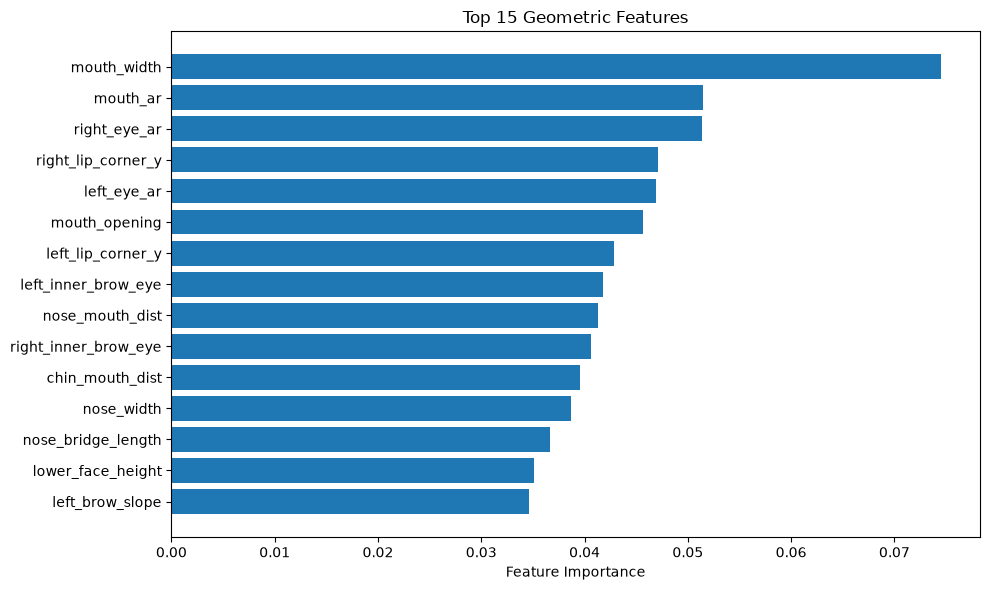

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

display(feature_importance.head(15))

plt.figure(figsize=(10, 6))
top_features = feature_importance.head(15).iloc[::-1]

plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Feature Importance")
plt.title("Top 15 Geometric Features")
plt.tight_layout()
plt.show()

## 22. Test Results and Interpretation

The completed evaluation on the official FER-2013 test split produced:
* Official test images: 7,178
* Successfully extracted landmark feature rows: 5,378
* Landmark-extraction coverage: 74.92%
* Test accuracy on successfully processed images (Random Forest, scaled 25 features): 56.32%
* Test Macro F1: 0.5180 (weighted F1: 0.5531)
* Test accuracy when the 1,800 failed images are counted as wrong: 42.2% (3,029 of 7,178)

The anatomical ablation study (validation set) showed that the **Lower Face (Mouth & Jaw)** provided the strongest regional features (Macro F1: 0.4497), followed by the upper face (0.3485) and the nose region (0.3154). The **Combined** 25-feature model performed best overall (Macro F1: 0.4947).However, landmark coverage is only 74.92%, the plan's 90% gate was not met, and sad and fear fail detection most often, so the results apply only to images where landmarks were found.

## 23. Raw Normalized Landmark Baseline

The project plan asks us to compare engineered measurements with normalized landmark coordinates. This section extracts the 68 normalized \((x,y)\) points for the same fixed manifest, caches them, and evaluates a linear SVM and an RBF SVM. The scaler is fitted on the training partition only. This extraction can take time on the full FER-2013 dataset.

In [52]:
from pathlib import Path
import pandas as pd
import numpy as np
import cv2
from tqdm.auto import tqdm

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report


# ============================================================
# 1. PREPARE MANIFEST AND CACHE
# ============================================================

PROCESSED_DIR = Path.cwd() / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

raw_csv = PROCESSED_DIR / "dlib_normalized_landmarks.csv"

manifest = geometry_manifest[
    ["image", "emotion", "partition"]
].copy()

manifest["image"] = (
    manifest["image"]
    .astype(str)
    .str.replace("\\", "/", regex=False)
)

if manifest["image"].duplicated().any():
    raise ValueError("Duplicate image paths found in geometry_manifest.")

raw_feature_columns = [
    f"lm_{i}_{axis}"
    for i in range(68)
    for axis in ["x", "y"]
]

required_columns = [
    "image",
    "emotion",
    "partition",
    "landmarks_extracted"
] + raw_feature_columns


# Load an existing checkpoint, if available.
if raw_csv.exists():

    print("Existing checkpoint found. Checking saved progress...")

    cached_df = pd.read_csv(raw_csv)

    missing_columns = [
        col for col in required_columns
        if col not in cached_df.columns
    ]

    if missing_columns:
        raise ValueError(
            "The existing cache has an incompatible format. "
            "Rename or delete dlib_normalized_landmarks.csv "
            "before starting again."
        )

    cached_df["image"] = (
        cached_df["image"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
    )

    # Keep only images belonging to the current manifest.
    cached_df = cached_df[
        cached_df["image"].isin(manifest["image"])
    ].copy()

    # Keep the latest saved record for each image.
    cached_df = cached_df.drop_duplicates(
        subset="image",
        keep="last"
    )

    # Check whether the saved metadata matches the current manifest.
    expected_metadata = manifest.set_index("image")
    cached_metadata = cached_df.set_index("image")

    valid_cached_images = []

    for image_name in cached_metadata.index:

        if (
            cached_metadata.loc[image_name, "emotion"]
            == expected_metadata.loc[image_name, "emotion"]
            and
            cached_metadata.loc[image_name, "partition"]
            == expected_metadata.loc[image_name, "partition"]
        ):
            valid_cached_images.append(image_name)

    cached_df = cached_df[
        cached_df["image"].isin(valid_cached_images)
    ].copy()

else:

    print("No checkpoint found. Starting fresh extraction.")

    cached_df = pd.DataFrame(columns=required_columns)


completed_images = set(cached_df["image"].astype(str))

remaining_manifest = manifest[
    ~manifest["image"].isin(completed_images)
].copy()

print("\nExtraction status:")
print("Total images:", len(manifest))
print("Already processed:", len(completed_images))
print("Remaining images:", len(remaining_manifest))


# ============================================================
# 2. CHECKPOINT SAVING FUNCTION
# ============================================================

def save_checkpoint(dataframe):

    temporary_file = raw_csv.with_name(
        raw_csv.stem + "_temporary.csv"
    )

    dataframe.to_csv(temporary_file, index=False)

    # Replace the old checkpoint with the new one.
    temporary_file.replace(raw_csv)


# ============================================================
# 3. EXTRACT NORMALIZED LANDMARKS WITH LIVE PROGRESS
# ============================================================

CHECKPOINT_INTERVAL = 100

new_records = []

progress = tqdm(
    remaining_manifest.itertuples(index=False),
    total=len(remaining_manifest),
    desc="Extracting facial landmarks",
    unit="image"
)

for row in progress:

    image_path = DATASET_DIR / row.image

    points_norm = None

    # Load image.
    gray = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if gray is not None:

        # First detection attempt.
        faces = face_detector(gray, 2)

        detection_image = gray
        scale = 1

        # Retry using a resized image if no face is detected.
        if len(faces) == 0:

            detection_image = cv2.resize(
                gray,
                None,
                fx=3,
                fy=3,
                interpolation=cv2.INTER_CUBIC
            )

            faces = face_detector(detection_image, 2)
            scale = 3

        # Extract landmarks only when exactly one face is detected.
        if len(faces) == 1:

            shape = landmark_predictor(
                detection_image,
                faces[0]
            )

            points = np.array(
                [
                    [
                        shape.part(i).x / scale,
                        shape.part(i).y / scale
                    ]
                    for i in range(68)
                ],
                dtype=float
            )

            points_norm = normalize_landmarks(points)

    # Prepare the record.
    record = {
        "image": row.image,
        "emotion": row.emotion,
        "partition": row.partition,
        "landmarks_extracted": False
    }

    # Store coordinates only if they are valid.
    if (
        points_norm is not None
        and np.isfinite(points_norm).all()
    ):

        record["landmarks_extracted"] = True

        for i in range(68):

            record[f"lm_{i}_x"] = points_norm[i, 0]
            record[f"lm_{i}_y"] = points_norm[i, 1]

    else:

        # Failed detections get NaN coordinates.
        for column in raw_feature_columns:
            record[column] = np.nan

    new_records.append(record)

    # Update the progress description.
    progress.set_postfix(
        processed=len(new_records),
        cached=len(completed_images)
    )

    # Save a checkpoint after every 100 new images.
    if len(new_records) % CHECKPOINT_INTERVAL == 0:

        updated_cache = pd.concat(
            [
                cached_df,
                pd.DataFrame(new_records)
            ],
            ignore_index=True
        )

        save_checkpoint(updated_cache)

        cached_df = updated_cache
        new_records = []

        progress.set_postfix_str(
            f"Checkpoint saved | Total: {len(cached_df)}"
        )


# Save the remaining records after extraction finishes.
if new_records:

    cached_df = pd.concat(
        [
            cached_df,
            pd.DataFrame(new_records)
        ],
        ignore_index=True
    )

save_checkpoint(cached_df)

print("\nLandmark extraction completed!")
print("Checkpoint saved at:", raw_csv)


# ============================================================
# 4. PREPARE SUCCESSFULLY EXTRACTED LANDMARKS
# ============================================================

raw_df = pd.read_csv(raw_csv)

raw_df["landmarks_extracted"] = (
    raw_df["landmarks_extracted"]
    .astype(str)
    .str.lower()
    .isin(["true", "1"])
)

raw_success = raw_df[
    raw_df["landmarks_extracted"]
].copy()

# Remove rows with invalid or missing coordinates.
raw_success = raw_success[
    np.isfinite(
        raw_success[raw_feature_columns].to_numpy(dtype=float)
    ).all(axis=1)
].copy()

raw_train = raw_success[
    raw_success["partition"] == "train"
]

raw_val = raw_success[
    raw_success["partition"] == "validation"
]

print("\nLandmark extraction summary:")
print("Total images:", len(manifest))
print("Successful extractions:", len(raw_success))
print("Failed extractions:", len(manifest) - len(raw_success))
print(
    "Landmark coverage:",
    f"{len(raw_success) / len(manifest):.2%}"
)


# ============================================================
# 5. TRAIN LINEAR AND RBF SVM MODELS
# ============================================================

if len(raw_train) == 0 or len(raw_val) == 0:
    raise ValueError(
        "Training or validation data is empty. "
        "Check landmark extraction and dataset partitions."
    )

X_raw_train = raw_train[
    raw_feature_columns
].to_numpy(dtype=float)

X_raw_val = raw_val[
    raw_feature_columns
].to_numpy(dtype=float)

y_raw_train = raw_train["emotion"]
y_raw_val = raw_val["emotion"]


print("\nScaling landmark coordinates...")

raw_scaler = StandardScaler()

X_raw_train_scaled = raw_scaler.fit_transform(
    X_raw_train
)

X_raw_val_scaled = raw_scaler.transform(
    X_raw_val
)


raw_models = {

    "Raw coordinates - Linear SVM": SVC(
        kernel="linear",
        class_weight="balanced",
        random_state=42
    ),

    "Raw coordinates - RBF SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    )
}


raw_results = []

for model_name, model in tqdm(
    raw_models.items(),
    desc="Training SVM models",
    unit="model"
):

    model.fit(
        X_raw_train_scaled,
        y_raw_train
    )

    predictions = model.predict(
        X_raw_val_scaled
    )

    raw_results.append({

        "Model": model_name,

        "Accuracy": accuracy_score(
            y_raw_val,
            predictions
        ),

        "Macro F1": f1_score(
            y_raw_val,
            predictions,
            average="macro"
        )
    })


# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

print("\nRaw Normalized Landmark Baseline Results:")

display(
    pd.DataFrame(raw_results)
)

print("\nFinal dataset information:")
print("Training samples:", len(raw_train))
print("Validation samples:", len(raw_val))
print("Successful landmark samples:", len(raw_success))
print("Cache file:", raw_csv)

Existing checkpoint found. Checking saved progress...

Extraction status:
Total images: 35887
Already processed: 35887
Remaining images: 0


Extracting facial landmarks: 0image [00:00, ?image/s]


Landmark extraction completed!
Checkpoint saved at: c:\Users\HP\Documents\MiniProject\data\processed\dlib_normalized_landmarks.csv

Landmark extraction summary:
Total images: 35887
Successful extractions: 26841
Failed extractions: 9046
Landmark coverage: 74.79%

Scaling landmark coordinates...


Training SVM models:   0%|          | 0/2 [00:00<?, ?model/s]


Raw Normalized Landmark Baseline Results:


,Model,Accuracy,Macro F1
0,Raw coordinates - Linear SVM,0.493798,0.415183
1,Raw coordinates - RBF SVM,0.547859,0.475547



Final dataset information:
Training samples: 17190
Validation samples: 4273
Successful landmark samples: 26841
Cache file: c:\Users\HP\Documents\MiniProject\data\processed\dlib_normalized_landmarks.csv


## 24. Random-Seed Stability and Validation Uncertainty

The plan recommends repeated trials and uncertainty reporting. The following cell repeats the geometry Random Forest with predeclared seeds on the existing training/validation split. It reports mean and standard deviation, plus a bootstrap interval for validation macro F1. These are validation estimates, not a replacement for the locked test result.

In [53]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score
import numpy as np
import pandas as pd

seed_values = [11, 22, 33, 44, 55]
seed_rows = []
seed_predictions = []

for seed in seed_values:
    model = RandomForestClassifier(
        n_estimators=200, class_weight="balanced",
        random_state=seed, n_jobs=-1
    )
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_val_scaled)
    seed_predictions.append(pred)
    seed_rows.append({
        "seed": seed,
        "accuracy": accuracy_score(y_val, pred),
        "macro_f1": f1_score(y_val, pred, average="macro")
    })

seed_results = pd.DataFrame(seed_rows)
display(seed_results)
print("Mean ± SD accuracy:",
      f"{seed_results.accuracy.mean():.4f} ± {seed_results.accuracy.std(ddof=1):.4f}")
print("Mean ± SD macro F1:",
      f"{seed_results.macro_f1.mean():.4f} ± {seed_results.macro_f1.std(ddof=1):.4f}")

# Bootstrap CI for the first predeclared seed's validation macro F1.
rng = np.random.default_rng(42)
reference_pred = seed_predictions[0]
y_true_array = np.asarray(y_val)
bootstrap_scores = []
for _ in range(1000):
    idx = rng.integers(0, len(y_true_array), len(y_true_array))
    bootstrap_scores.append(
        f1_score(y_true_array[idx], reference_pred[idx],
                 labels=rf_model.classes_, average="macro", zero_division=0)
    )
ci_low, ci_high = np.percentile(bootstrap_scores, [2.5, 97.5])
print(f"Seed {seed_values[0]} validation macro-F1 95% bootstrap CI: [{ci_low:.4f}, {ci_high:.4f}]")

EXPERIMENTS_DIR = Path.cwd() / "results" / "experiments"
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

seed_results.to_csv(
    EXPERIMENTS_DIR / "geometry_random_seed_validation.csv",
    index=False
)

,seed,accuracy,macro_f1
0,11,0.548093,0.498569
1,22,0.546923,0.496084
2,33,0.547391,0.495337
3,44,0.553475,0.497577
4,55,0.552071,0.497153


Mean ± SD accuracy: 0.5496 ± 0.0030
Mean ± SD macro F1: 0.4969 ± 0.0013
Seed 11 validation macro-F1 95% bootstrap CI: [0.4755, 0.5199]


## 25. Synthetic Geometry Unit Tests

These lightweight tests check normalization invariance to translation, scale, and in-plane rotation, and verify that the normalized landmark output is finite and has the expected shape. They test the geometry calculations independently of FER labels.

In [54]:
def run_geometry_unit_tests():
    rng = np.random.default_rng(7)
    points = rng.normal(size=(68, 2))

    # Give the eye regions distinct, non-coincident centres.
    points[36:42] += np.array([0.0, 0.0])
    points[42:48] += np.array([2.0, 0.2])

    base = normalize_landmarks(points)
    assert base is not None and base.shape == (68, 2)
    assert np.isfinite(base).all()

    # Translation and positive scale should not change normalized geometry.
    translated_scaled = normalize_landmarks(points * 3.5 + np.array([120.0, -45.0]))
    assert np.allclose(base, translated_scaled, atol=1e-7)

    # In-plane rotation should be removed by eye-line alignment.
    theta = np.deg2rad(23)
    rotation = np.array([[np.cos(theta), -np.sin(theta)],
                         [np.sin(theta),  np.cos(theta)]])
    rotated = normalize_landmarks(points @ rotation.T)
    assert np.allclose(base, rotated, atol=1e-7)

    # Coincident eye centres must be rejected safely.
    degenerate = points.copy()
    degenerate[42:48] = degenerate[36:42].mean(axis=0)
    assert normalize_landmarks(degenerate) is None

    print("All synthetic geometry unit tests passed.")

run_geometry_unit_tests()

All synthetic geometry unit tests passed.


## 26. Explicit Landmark Quality Audit

The earlier manifest records extraction as success/failure. This audit re-runs dlib on the fixed manifest and assigns interpretable outcomes: `accepted`, `unreadable_image`, `no_face`, `multiple_faces`, `implausible_landmarks`, or `detector_error`. A dlib 68-point predictor does not expose a calibrated landmark-confidence score, so confidence is recorded as unavailable rather than fabricated. The audit can take substantial time on the full dataset. The plan's 90% pilot threshold must be assessed on the specified pilot subset; overall test coverage is not a substitute.

In [55]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path

quality_rows = []
for row in geometry_manifest.itertuples(index=False):
    image_path = DATASET_DIR / str(row.image)
    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    status = "detector_error"
    n_faces = 0
    points = None
    if image is None:
        status = "unreadable_image"
    else:
        try:
            faces = face_detector(image, 1)
            detection_image, scale = image, 1
            if len(faces) == 0:
                enlarged = cv2.resize(image, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)
                faces = face_detector(enlarged, 0)
                detection_image, scale = enlarged, 3
            n_faces = len(faces)
            if n_faces == 0:
                status = "no_face"
            elif n_faces > 1:
                status = "multiple_faces"
            else:
                shape = landmark_predictor(detection_image, faces[0])
                points = np.array([[shape.part(i).x / scale, shape.part(i).y / scale] for i in range(68)], dtype=float)
                h, w = image.shape[:2]
                inside = ((points[:, 0] >= 0) & (points[:, 0] < w) & (points[:, 1] >= 0) & (points[:, 1] < h)).all()
                eye_distance = np.linalg.norm(points[42:48].mean(axis=0) - points[36:42].mean(axis=0))
                face_width = faces[0].right() - faces[0].left()
                plausible = (np.isfinite(points).all() and inside and eye_distance >= 2 and face_width >= 8)
                status = "accepted" if plausible else "implausible_landmarks"
        except Exception:
            status = "detector_error"
    quality_rows.append({"image": str(row.image).replace("\\", "/"), "emotion": row.emotion,
                         "partition": row.partition, "quality_status": status,
                         "detected_face_count": n_faces, "landmark_confidence": np.nan})

quality_audit_df = pd.DataFrame(quality_rows)

AUDITS_DIR = Path.cwd() / "results" / "audits"
AUDITS_DIR.mkdir(parents=True, exist_ok=True)

quality_audit_df.to_csv(
    AUDITS_DIR / "dlib_landmark_quality_audit.csv",
    index=False
)
display(quality_audit_df["quality_status"].value_counts().rename("count").to_frame())
display(pd.crosstab(quality_audit_df["emotion"], quality_audit_df["quality_status"], normalize="index").round(3))
quality_coverage = (quality_audit_df["quality_status"] == "accepted").mean()
print(f"Audited-manifest accepted coverage: {quality_coverage:.2%}")
print("90% target met on this manifest:", quality_coverage >= 0.90)
print("Note: this is not a separately sampled 700-image pilot unless the manifest itself is that pilot.")
print("dlib landmark confidence: unavailable from this predictor interface.")


,count
quality_status,
implausible_landmarks,21066
no_face,8281
accepted,6540


quality_status,accepted,implausible_landmarks,no_face
emotion,,,
angry,0.206,0.560,0.234
disgust,0.031,0.814,0.155
fear,0.111,0.587,0.302
happy,0.219,0.625,0.156
neutral,0.244,0.574,0.182
sad,0.172,0.471,0.358
surprise,0.103,0.701,0.196


Audited-manifest accepted coverage: 18.22%
90% target met on this manifest: False
Note: this is not a separately sampled 700-image pilot unless the manifest itself is that pilot.
dlib landmark confidence: unavailable from this predictor interface.


### 26A. Stratified 700-Image Landmark Pilot

The plan specifies a 700-image pilot. This cell selects 100 images per emotion from the completed quality audit, using a fixed random seed, and reports overall and class-wise acceptance. If any class has fewer than 100 audited records, the cell stops rather than silently producing a smaller pilot. The 90% gate is evaluated on this pilot only.

In [56]:
pilot_parts=[]
for emotion in emotions:
    class_rows=quality_audit_df[quality_audit_df.emotion==emotion]
    if len(class_rows)<100:
        raise ValueError(f"Cannot form the required 700-image pilot: {emotion} has only {len(class_rows)} audited rows.")
    pilot_parts.append(class_rows.sample(n=100,random_state=42))
pilot_700=pd.concat(pilot_parts,ignore_index=True)
pilot_coverage=(pilot_700.quality_status=="accepted").mean()
print("Pilot size:",len(pilot_700))
print("Overall accepted coverage:",f"{pilot_coverage:.2%}")
print("90% pilot gate:","PASS" if pilot_coverage>=0.90 else "NOT MET")
display(pd.crosstab(pilot_700.emotion,pilot_700.quality_status,normalize="index").round(3))

AUDITS_DIR = Path.cwd() / "results" / "audits"
AUDITS_DIR.mkdir(parents=True, exist_ok=True)

pilot_700.to_csv(
    AUDITS_DIR / "dlib_700_image_stratified_pilot.csv",
    index=False
)


Pilot size: 700
Overall accepted coverage: 15.14%
90% pilot gate: NOT MET


quality_status,accepted,implausible_landmarks,no_face
emotion,,,
angry,0.17,0.57,0.26
disgust,0.03,0.77,0.20
fear,0.11,0.56,0.33
happy,0.25,0.55,0.20
neutral,0.23,0.62,0.15
sad,0.17,0.44,0.39
surprise,0.10,0.64,0.26


### 26B. Checks which rule rejected the 700-image pilot images marked implausible_landmarks, to explain the gap between the audit coverage and the extraction coverage

In [57]:
rows = []
for row in pilot_700[pilot_700["quality_status"] == "implausible_landmarks"].itertuples(index=False):
    image = cv2.imread(str(DATASET_DIR / row.image), cv2.IMREAD_GRAYSCALE)
    faces = face_detector(image, 1); det, scale = image, 1
    if len(faces) == 0:
        det, scale = cv2.resize(image, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC), 3
        faces = face_detector(det, 0)
    if len(faces) != 1:
        continue
    shape = landmark_predictor(det, faces[0])
    pts = np.array([[shape.part(i).x / scale, shape.part(i).y / scale] for i in range(68)], float)
    h, w = image.shape[:2]
    over = np.maximum.reduce([-pts[:, 0], pts[:, 0] - (w - 1), -pts[:, 1], pts[:, 1] - (h - 1), np.zeros(68)])
    rows.append({"points_outside": int((over > 0).sum()), "max_overshoot_frac": float(over.max() / max(h, w)),
                 "eye_distance": float(np.linalg.norm(pts[42:48].mean(0) - pts[36:42].mean(0))),
                 "face_width": faces[0].right() - faces[0].left()})
diag = pd.DataFrame(rows)
print(f"images checked: {len(diag)}")
print(f"at least one landmark outside the image: {(diag.points_outside > 0).mean():.0%}")
print(f"all points within 15% of the border   : {(diag.max_overshoot_frac <= 0.15).mean():.0%}")
print(f"eye distance < 2 px or face width < 8 : {((diag.eye_distance < 2) | (diag.face_width < 8)).mean():.0%}")

images checked: 415
at least one landmark outside the image: 100%
all points within 15% of the border   : 99%
eye distance < 2 px or face width < 8 : 0%


**26B result.** Of the 415 pilot images rejected as `implausible_landmarks`, all had at least one landmark outside the 48 x 48 frame, 99% had every landmark within 15% of the image border, and none failed the eye-distance or face-width checks. The strict rule that requires all 68 points to lie inside the image therefore caused the rejections. FER-2013 faces are tightly cropped, so jaw and eyebrow points often fall just outside the frame. With a 15% tolerance the pilot's accepted coverage would be about 74% (estimated as (106 + 0.99 x 415) / 700), consistent with the 74.92% extraction coverage. The 90% gate is still not met, so the audit's 15.14% should be read as the result of the strict border rule, not as detector failure.

## 27. Unit Tests for Five Engineered Geometric Features

These tests validate five feature calculations against independently computed reference formulas on deterministic synthetic 68-point coordinates. They test the implementation, not whether the features are sufficient to identify an emotion.

In [58]:
# Minimal dlib-shape stand-in so feature extraction can be tested without image files.
class _MockPart:
    def __init__(self, x, y): self.x, self.y = float(x), float(y)
class _MockShape:
    def __init__(self, pts): self._pts = np.asarray(pts, dtype=float)
    def part(self, i): return _MockPart(*self._pts[i])

def test_five_geometric_features():
    # Deterministic, non-degenerate landmark layout with separated eye centres.
    pts = np.zeros((68, 2), dtype=float)
    for i in range(68): pts[i] = [40 + (i % 10) * 3, 30 + (i // 10) * 4]
    # Eye contours (points 36:48)
    pts[36:42] = [[50,50],[52,48],[55,48],[58,50],[55,52],[52,52]]
    pts[42:48] = [[70,50],[72,48],[75,48],[78,50],[75,52],[72,52]]
    # Nose and mouth/jaw anchors
    pts[27]=[64,55]; pts[30]=[64,67]; pts[31]=[59,68]; pts[35]=[69,68]; pts[33]=[64,70]
    pts[48]=[52,80]; pts[51]=[64,78]; pts[54]=[76,80]; pts[57]=[64,86]
    pts[62]=[64,79]; pts[66]=[64,85]; pts[8]=[64,105]; pts[3]=[43,88]; pts[13]=[85,88]
    features = calculate_geometric_features(_MockShape(pts))
    norm = normalize_landmarks(pts)
    def d(a,b): return np.linalg.norm(norm[a]-norm[b])
    expected = {"nose_width": d(31,35), "mouth_width": d(48,54),
                "mouth_opening": d(51,57), "jaw_width": d(3,13),
                "lower_face_height": d(33,8)}
    for name, value in expected.items():
        assert name in features and np.isclose(features[name], value, atol=1e-10), (name, features.get(name), value)
    assert np.isfinite(list(features.values())).all()
    print("PASS: five geometric feature formulas (nose_width, mouth_width, mouth_opening, jaw_width, lower_face_height)")

test_five_geometric_features()


PASS: five geometric feature formulas (nose_width, mouth_width, mouth_opening, jaw_width, lower_face_height)


## 28. Pixel-Coordinate vs Normalized-Landmark Baseline

The existing coordinate baseline uses normalized landmarks. This additional experiment extracts the same 68 points in original image-pixel coordinates and compares linear/RBF SVMs against normalized coordinates on the same fixed train/validation partitions. Both scalers are fitted on training data only. Pixel coordinates are intentionally sensitive to image position and scale; this is a baseline comparison, not a recommended final representation. Extraction is cached and may take a long time.

In [59]:
# ============================================================
# SECTION 28: PIXEL-COORDINATE VS NORMALIZED-LANDMARK BASELINE
# ============================================================

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import time
from tqdm.auto import tqdm

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score


# ============================================================
# 1. PREPARE MANIFEST AND CACHE
# ============================================================

PROCESSED_DIR = Path.cwd() / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pixel_cache = PROCESSED_DIR / "dlib_pixel_landmarks.csv"

manifest_px = geometry_manifest[
    ["image", "emotion", "partition"]
].copy()

manifest_px["image"] = (
    manifest_px["image"]
    .astype(str)
    .str.replace("\\", "/", regex=False)
)

pixel_cols = [
    f"px_{i}_{axis}"
    for i in range(68)
    for axis in ["x", "y"]
]

required_cols = [
    "image", "emotion", "partition",
    "landmarks_extracted"
] + pixel_cols


# ============================================================
# 2. LOAD EXISTING CHECKPOINT
# ============================================================

if pixel_cache.exists():

    print("Existing pixel-coordinate checkpoint found.")

    pixel_df = pd.read_csv(pixel_cache)

    missing_cols = [
        col for col in required_cols
        if col not in pixel_df.columns
    ]

    if missing_cols:
        raise ValueError(
            "Existing pixel cache has an incompatible format. "
            "Rename or delete dlib_pixel_landmarks.csv "
            "and run this cell again."
        )

    pixel_df["image"] = (
        pixel_df["image"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
    )

    pixel_df = pixel_df[
        pixel_df["image"].isin(manifest_px["image"])
    ].copy()

    pixel_df = pixel_df.drop_duplicates(
        subset="image",
        keep="last"
    )

    # Verify cached labels and partitions.
    expected = manifest_px.set_index("image")
    cached = pixel_df.set_index("image")

    valid_images = []

    for image_name in cached.index:

        if (
            cached.loc[image_name, "emotion"]
            == expected.loc[image_name, "emotion"]
            and
            cached.loc[image_name, "partition"]
            == expected.loc[image_name, "partition"]
        ):
            valid_images.append(image_name)

    pixel_df = pixel_df[
        pixel_df["image"].isin(valid_images)
    ].copy()

else:

    print("No existing checkpoint. Starting fresh.")

    pixel_df = pd.DataFrame(columns=required_cols)


completed_images = set(pixel_df["image"].astype(str))

remaining = manifest_px[
    ~manifest_px["image"].isin(completed_images)
].copy()

print("\nExtraction status:")
print("Total images:", len(manifest_px))
print("Already processed:", len(completed_images))
print("Remaining:", len(remaining))


# ============================================================
# 3. CHECKPOINT FUNCTION
# ============================================================

def save_pixel_checkpoint(df):

    temp_file = pixel_cache.with_name(
        pixel_cache.stem + "_temporary.csv"
    )

    df.to_csv(temp_file, index=False)
    temp_file.replace(pixel_cache)


# ============================================================
# 4. EXTRACT PIXEL COORDINATES WITH PROGRESS BAR
# ============================================================

CHECKPOINT_INTERVAL = 100

new_rows = []

progress = tqdm(
    remaining.itertuples(index=False),
    total=len(remaining),
    desc="Extracting pixel landmarks",
    unit="image"
)

for r in progress:

    image_path = DATASET_DIR / r.image

    gray = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    points = None

    if gray is not None:

        faces = face_detector(gray, 2)

        detection_image = gray
        scale = 1

        if len(faces) == 0:

            detection_image = cv2.resize(
                gray,
                None,
                fx=3,
                fy=3,
                interpolation=cv2.INTER_CUBIC
            )

            faces = face_detector(detection_image, 2)
            scale = 3

        if len(faces) == 1:

            shape = landmark_predictor(
                detection_image,
                faces[0]
            )

            points = np.array(
                [
                    [
                        shape.part(i).x / scale,
                        shape.part(i).y / scale
                    ]
                    for i in range(68)
                ],
                dtype=float
            )

    record = {
        "image": r.image,
        "emotion": r.emotion,
        "partition": r.partition,
        "landmarks_extracted": False
    }

    if points is not None and np.isfinite(points).all():

        record["landmarks_extracted"] = True

        for i in range(68):

            record[f"px_{i}_x"] = points[i, 0]
            record[f"px_{i}_y"] = points[i, 1]

    else:

        for col in pixel_cols:
            record[col] = np.nan

    new_rows.append(record)

    progress.set_postfix(
        new=len(new_rows),
        cached=len(completed_images)
    )

    # Save every 100 newly processed images.
    if len(new_rows) >= CHECKPOINT_INTERVAL:

        pixel_df = pd.concat(
            [
                pixel_df,
                pd.DataFrame(new_rows)
            ],
            ignore_index=True
        )

        save_pixel_checkpoint(pixel_df)

        new_rows = []

        progress.set_postfix_str(
            f"Checkpoint saved | {len(pixel_df)} total"
        )


# Save remaining records.
if new_rows:

    pixel_df = pd.concat(
        [
            pixel_df,
            pd.DataFrame(new_rows)
        ],
        ignore_index=True
    )

save_pixel_checkpoint(pixel_df)

print("\nPixel landmark extraction completed!")
print("Checkpoint:", pixel_cache)


# ============================================================
# 5. PREPARE TRAINING AND VALIDATION DATA
# ============================================================

pixel_df = pd.read_csv(pixel_cache)

pixel_df["landmarks_extracted"] = (
    pixel_df["landmarks_extracted"]
    .astype(str)
    .str.lower()
    .isin(["true", "1"])
)

pix_ok = pixel_df[
    pixel_df["landmarks_extracted"]
].copy()

pix_ok = pix_ok[
    np.isfinite(
        pix_ok[pixel_cols].to_numpy(dtype=float)
    ).all(axis=1)
].copy()

pix_tr = pix_ok[
    pix_ok["partition"] == "train"
]

pix_va = pix_ok[
    pix_ok["partition"] == "validation"
]

print("\nPixel-coordinate extraction summary:")
print("Successful extractions:", len(pix_ok))
print("Training samples:", len(pix_tr))
print("Validation samples:", len(pix_va))
print(
    "Coverage:",
    f"{len(pix_ok) / len(manifest_px):.2%}"
)

if len(pix_tr) == 0 or len(pix_va) == 0:

    raise ValueError(
        "Training or validation dataset is empty."
    )


# ============================================================
# 6. SCALE FEATURES
# ============================================================

Xpt = pix_tr[pixel_cols].to_numpy(dtype=float)
Xpv = pix_va[pixel_cols].to_numpy(dtype=float)

ypt = pix_tr["emotion"]
ypv = pix_va["emotion"]

sc = StandardScaler()

Xpt_scaled = sc.fit_transform(Xpt)
Xpv_scaled = sc.transform(Xpv)


# ============================================================
# 7. TRAIN LINEAR AND RBF SVM WITH PROGRESS
# ============================================================

pixel_models = {

    "Linear SVM": SVC(
        kernel="linear",
        class_weight="balanced",
        random_state=42
    ),

    "RBF SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    )
}

pixel_results = []

for model_name, clf in tqdm(
    pixel_models.items(),
    desc="Training pixel-coordinate SVMs",
    unit="model"
):

    print(f"\nStarting {model_name}...")

    start_time = time.time()

    clf.fit(
        Xpt_scaled,
        ypt
    )

    training_time = time.time() - start_time

    print(
        f"{model_name} completed in "
        f"{training_time / 60:.2f} minutes"
    )

    pred = clf.predict(Xpv_scaled)

    pixel_results.append({

        "representation": "Unnormalized pixel coordinates",

        "kernel": model_name,

        "accuracy": accuracy_score(
            ypv,
            pred
        ),

        "macro_f1": f1_score(
            ypv,
            pred,
            average="macro"
        ),

        "training_time_minutes": training_time / 60
    })


# ============================================================
# 8. ADD NORMALIZED COORDINATE RESULTS FROM SECTION 24
# ============================================================

if "raw_results" in globals():

    for rec in raw_results:

        pixel_results.append({

            "representation": "Normalized coordinates",

            "kernel": rec["Model"].split(" - ")[-1],

            "accuracy": rec["Accuracy"],

            "macro_f1": rec["Macro F1"],

            "training_time_minutes": np.nan
        })

else:

    print(
        "Run Section 24 first to include normalized "
        "coordinate results."
    )


# ============================================================
# 9. DISPLAY AND SAVE COMPARISON
# ============================================================

pixel_comparison = pd.DataFrame(pixel_results)

print("\nPixel vs Normalized Coordinate Comparison:")

display(pixel_comparison)

EXPERIMENTS_DIR = Path.cwd() / "results" / "experiments"
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

pixel_comparison.to_csv(
    EXPERIMENTS_DIR / "pixel_vs_normalized_coordinate_comparison.csv",
    index=False
)

print(
    "\nComparison saved to "
    "results/experiments/pixel_vs_normalized_coordinate_comparison.csv"
)

Existing pixel-coordinate checkpoint found.

Extraction status:
Total images: 35887
Already processed: 35887
Remaining: 0


Extracting pixel landmarks: 0image [00:00, ?image/s]


Pixel landmark extraction completed!
Checkpoint: c:\Users\HP\Documents\MiniProject\data\processed\dlib_pixel_landmarks.csv

Pixel-coordinate extraction summary:
Successful extractions: 27997
Training samples: 17930
Validation samples: 4478
Coverage: 78.01%


Training pixel-coordinate SVMs:   0%|          | 0/2 [00:00<?, ?model/s]


Starting Linear SVM...
Linear SVM completed in 5.62 minutes

Starting RBF SVM...
RBF SVM completed in 2.11 minutes

Pixel vs Normalized Coordinate Comparison:


,representation,kernel,accuracy,macro_f1,training_time_minutes
0,Unnormalized pixel coordinates,Linear SVM,0.487494,0.412192,5.619560
1,Unnormalized pixel coordinates,RBF SVM,0.491514,0.417713,2.114851
2,Normalized coordinates,Linear SVM,0.493798,0.415183,NaN
3,Normalized coordinates,RBF SVM,0.547859,0.475547,NaN



Comparison saved to results/experiments/pixel_vs_normalized_coordinate_comparison.csv


## 29. High-Quality vs All-Detected Landmark Subset

This comparison applies a transparent, conservative geometry plausibility screen to the normalized landmark cache: all coordinates must be finite and the normalized face must remain within a broad facial-region envelope. It compares the all-detected subset with the screened subset on validation data. The envelope is an operational quality filter, not a clinically validated confidence score; report its thresholds and coverage alongside performance.

In [61]:

# Uses the normalized 68-point cache created in Section 24.
if "raw_df" not in globals():
    raise RuntimeError("Run Section 24 first to create/load raw_df.")

lm_cols = [f"lm_{i}_{a}" for i in range(68) for a in ["x", "y"]]

qdf = raw_df.copy()
coords = qdf[lm_cols].to_numpy(dtype=float)

finite = np.isfinite(coords).all(axis=1)

# Broad envelope in eye-distance-normalized coordinates; deliberately permissive.
xy = coords.reshape(-1, 68, 2)

envelope = (
    (xy[:, :, 0] >= -3.0) &
    (xy[:, :, 0] <= 3.0) &
    (xy[:, :, 1] >= -3.5) &
    (xy[:, :, 1] <= 3.5)
).all(axis=1)

qdf["high_quality_geometry"] = (
    qdf["landmarks_extracted"].eq(True) &
    finite &
    envelope
)

print("All detected rows:", int(qdf.landmarks_extracted.eq(True).sum()))
print("High-quality screened rows:", int(qdf.high_quality_geometry.sum()))

print(
    "Screen retention among detected:",
    f"{qdf.high_quality_geometry.sum() / max(1, qdf.landmarks_extracted.eq(True).sum()):.2%}"
)

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

quality_rows = []

for subset_name, mask in [
    ("All detected", qdf.landmarks_extracted.eq(True)),
    ("High-quality screened", qdf.high_quality_geometry)
]:
    subset = qdf[mask]

    tr = subset[subset.partition == "train"]
    va = subset[subset.partition == "validation"]

    if len(tr) == 0 or len(va) == 0:
        continue

    sx = StandardScaler()
    xt = sx.fit_transform(tr[lm_cols])
    xv = sx.transform(va[lm_cols])

    clf = RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    clf.fit(xt, tr.emotion)
    pred = clf.predict(xv)

    quality_rows.append({
        "subset": subset_name,
        "train_n": len(tr),
        "validation_n": len(va),
        "accuracy": accuracy_score(va.emotion, pred),
        "macro_f1": f1_score(va.emotion, pred, average="macro")
    })

# Convert results into a DataFrame
quality_comparison = pd.DataFrame(quality_rows)

# Save experiment results
EXPERIMENTS_DIR = Path.cwd() / "results" / "experiments"
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

quality_comparison.to_csv(
    EXPERIMENTS_DIR / "high_quality_vs_all_landmarks.csv",
    index=False
)

print("\nQuality comparison results:")
display(quality_comparison)

print("\nSaved:", EXPERIMENTS_DIR / "high_quality_vs_all_landmarks.csv")


All detected rows: 26841
High-quality screened rows: 26838
Screen retention among detected: 99.99%

Quality comparison results:


,subset,train_n,validation_n,accuracy,macro_f1
0,All detected,17190,4273,0.560964,0.509044
1,High-quality screened,17187,4273,0.557688,0.505168



Saved: c:\Users\HP\Documents\MiniProject\results\experiments\high_quality_vs_all_landmarks.csv


## 30. Robustness Checks: Blur, Brightness, Rotation, and Landmark Dropout

The following held-out evaluation applies fixed perturbations to a reproducible sample of official-test images. It re-detects landmarks after image-level perturbations and reports both landmark coverage and classification performance. Landmark dropout is tested separately by perturbing a fraction of detected points before feature extraction. These are stress tests, not model-tuning experiments. Run after the original model and feature columns are available; computation depends on dlib speed.

In [62]:
import cv2, numpy as np, pandas as pd, time
from sklearn.metrics import accuracy_score, f1_score

# Deterministic test sample, capped to keep the robustness audit manageable.
robust_base=test_evaluation_df.sample(n=min(350,len(test_evaluation_df)),random_state=42).copy()

def detect_features_from_gray(gray):
    faces=face_detector(gray,1); det=gray; scale=1
    if len(faces)==0:
        det=cv2.resize(gray,None,fx=3,fy=3,interpolation=cv2.INTER_CUBIC); faces=face_detector(det,0); scale=3
    if len(faces)!=1: return None
    sh=landmark_predictor(det,faces[0])
    return np.array([[sh.part(i).x/scale,sh.part(i).y/scale] for i in range(68)],dtype=float)

class _Point:
    def __init__(self,x,y): self.x=float(x); self.y=float(y)
class _Shape:
    def __init__(self,p): self.p=p
    def part(self,i): return _Point(*self.p[i])

def feature_row_from_points(points):
    return calculate_geometric_features(_Shape(points))

robust_results=[]
for condition in ["original","gaussian_blur","brightness_dim","brightness_bright","rotation_10deg"]:
    records=[]
    for r in robust_base.itertuples(index=False):
        image=cv2.imread(str(DATASET_DIR / str(r.image)))
        if image is None: continue
        gray=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
        if condition=="gaussian_blur": gray=cv2.GaussianBlur(gray,(7,7),1.5)
        elif condition=="brightness_dim": gray=cv2.convertScaleAbs(gray,alpha=0.70,beta=-20)
        elif condition=="brightness_bright": gray=cv2.convertScaleAbs(gray,alpha=1.25,beta=25)
        elif condition=="rotation_10deg":
            h,w=gray.shape; M=cv2.getRotationMatrix2D((w/2,h/2),10,1.0); gray=cv2.warpAffine(gray,M,(w,h),borderMode=cv2.BORDER_REPLICATE)
        pts=detect_features_from_gray(gray)
        if pts is None: continue
        f=feature_row_from_points(pts)
        if f is not None and np.isfinite(list(f.values())).all(): records.append((r.emotion,f))
    if records:
        rdf=pd.DataFrame([x[1] for x in records])[feature_columns]
        pred=rf_model.predict(scaler.transform(rdf))
        truth=[x[0] for x in records]
        robust_results.append({"condition":condition,"sample_n":len(robust_base),"detected_n":len(records),"coverage":len(records)/len(robust_base),"accuracy":accuracy_score(truth,pred),"macro_f1":f1_score(truth,pred,average="macro")})

# Landmark dropout: randomly replace 10% of points with local-neighbour interpolation
# on detected points from the same reproducible sample.
rng=np.random.default_rng(42); dropout_records=[]
for r in robust_base.itertuples(index=False):
    image=cv2.imread(str(DATASET_DIR / str(r.image)))
    if image is None: continue
    pts=detect_features_from_gray(cv2.cvtColor(image,cv2.COLOR_BGR2GRAY))
    if pts is None: continue
    perturbed=pts.copy(); ids=rng.choice(68,size=max(1,round(0.10*68)),replace=False)
    for i in ids:
        neighbours=[j for j in (i-1,i+1) if 0<=j<68]
        perturbed[i]=pts[neighbours].mean(axis=0) if neighbours else pts[i]
    f=feature_row_from_points(perturbed)
    if f is not None and np.isfinite(list(f.values())).all(): dropout_records.append((r.emotion,f))
if dropout_records:
    dx=pd.DataFrame([x[1] for x in dropout_records])[feature_columns]
    dp=rf_model.predict(scaler.transform(dx)); dt=[x[0] for x in dropout_records]
    robust_results.append({"condition":"10% landmark dropout (synthetic)","sample_n":len(robust_base),"detected_n":len(dropout_records),"coverage":len(dropout_records)/len(robust_base),"accuracy":accuracy_score(dt,dp),"macro_f1":f1_score(dt,dp,average="macro")})
robustness_df=pd.DataFrame(robust_results); display(robustness_df)

EXPERIMENTS_DIR = Path.cwd() / "results" / "experiments"
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

robustness_df.to_csv(
    EXPERIMENTS_DIR / "geometry_robustness_results.csv",
    index=False
)


,condition,sample_n,detected_n,coverage,accuracy,macro_f1
0,original,350,273,0.780000,0.538462,0.420244
1,gaussian_blur,350,145,0.414286,0.441379,0.359320
2,brightness_dim,350,269,0.768571,0.539033,0.421440
3,brightness_bright,350,264,0.754286,0.507576,0.392971
4,rotation_10deg,350,236,0.674286,0.546610,0.499754
5,10% landmark dropout (synthetic),350,273,0.780000,0.498168,0.384186


## 31. Per-Image Inference-Time Measurement

This benchmark measures the complete geometry inference path (image read, dlib detection, 68-point prediction, feature extraction, scaling, and Random Forest prediction) on a fixed sample. Report mean, median, and 95th-percentile latency; results depend on hardware and should be accompanied by the machine/runtime details.

In [63]:
import time, numpy as np, pandas as pd, cv2

latency_sample=test_evaluation_df.sample(n=min(200,len(test_evaluation_df)),random_state=21)
latencies=[]; latency_status=[]
for r in latency_sample.itertuples(index=False):
    t0=time.perf_counter(); image=cv2.imread(str(DATASET_DIR / str(r.image)))
    status="accepted"
    if image is None: status="unreadable_image"
    else:
        gray=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
        pts=detect_features_from_gray(gray)
        if pts is None: status="no_single_face"
        else:
            f=feature_row_from_points(pts)
            if f is None or not np.isfinite(list(f.values())).all(): status="invalid_features"
            else:
                row=pd.DataFrame([f])[feature_columns]
                rf_model.predict(scaler.transform(row))
    latencies.append((time.perf_counter()-t0)*1000); latency_status.append(status)
latency_df=pd.DataFrame({"latency_ms":latencies,"status":latency_status})
print("Measured images:",len(latency_df))
print("Successful end-to-end predictions:",(latency_df.status=="accepted").sum())
print("Latency (ms) including failed attempts:")
display(latency_df.latency_ms.agg(["mean","median",lambda x:x.quantile(.95)]).rename(index={"<lambda_0>":"p95"}).to_frame("milliseconds"))
print("Latency status counts:"); display(latency_df.status.value_counts().to_frame("count"))

EXPERIMENTS_DIR = Path.cwd() / "results" / "experiments"
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

latency_df.to_csv(
    EXPERIMENTS_DIR / "geometry_inference_latency.csv",
    index=False
)


Measured images: 200
Successful end-to-end predictions: 148
Latency (ms) including failed attempts:


,milliseconds
mean,47.200335
median,51.444500
<lambda>,92.084360


Latency status counts:


,count
status,
accepted,148
no_single_face,52


## 32. Reproducibility, Environment, and Project Artifacts

To support reproducibility, this section documents the required software environment, repository structure, and execution workflow.

**Software Stack & Environment**
* **Language:** Python 3.11+ (an isolated conda or venv environment is recommended).
* **Core Dependencies:** `dlib` (68-point shape predictor), `opencv-python-headless`, `scikit-learn`, `pandas`, `numpy`, `matplotlib`, and `joblib`.

**Repository & Artifact Structure**
* `data/FER-2013/` — FER-2013 dataset directory with the expected train and test folders.
* `shape_predictor_68_face_landmarks.dat` — Pretrained dlib 68-point facial shape predictor.
* `dlib_geometry_train.csv` and `dlib_geometry_test.csv` — Geometry feature tables and extraction metadata.
* `dlib_geometry_model_expanded.joblib` — Serialized Random Forest classifier, fitted scaler, feature-column order, and emotion labels.

**Execution Workflow**
1. **Environment and detector setup (Sections 1–5.2):** Check dependencies, load the predictor, inspect the dataset, and prepare the shared manifest.
2. **Landmark and feature preparation (Sections 6–9):** Visualize samples, define normalization and feature extraction, build the training features, and verify the resulting table.
3. **Baseline modelling (Sections 10–15):** Train and validate classifiers, extract official-test features, evaluate the selected model, perform anatomical ablation, and save the model artifacts.
4. **Core audits and interpretation (Sections 16–22):** Check schemas and coverage, inspect errors and feature importance, and report the recorded test results.
5. **Additional experiments (Sections 24–32):** Run coordinate baselines, stability and unit tests, quality audits, robustness experiments, and inference-time measurement. Some cells repeat dlib detection over many images and may take substantial time.

Run cells in notebook order unless a section explicitly documents a prerequisite. Do not report results for an experiment until its cells have completed successfully.

To guarantee full reproducibility, this section documents the required software environment, repository structure, and sequential execution steps necessary to regenerate all experimental outputs.

## 33. Single-Image Emotion Prediction Demo

Predicted Emotion: SURPRISE\n
Class Probabilities:
  angry: 15.00%
  disgust: 0.50%
  fear: 28.00%
  happy: 8.50%
  neutral: 1.00%
  sad: 1.50%
  surprise: 45.50%


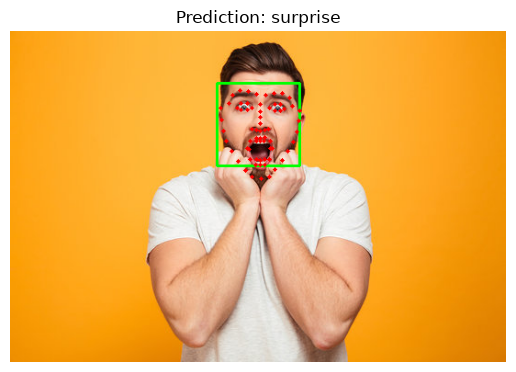

In [64]:
import cv2
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load the saved pipeline artifacts
MODEL_PATH = (
    Path.cwd()
    / "models"
    / "dlib_geometry_model_expanded.joblib"
)

artifacts = joblib.load(MODEL_PATH)
rf_model = artifacts["model"]
scaler = artifacts["scaler"]
feature_cols = artifacts["feature_columns"]

# 2. Load and preprocess the real image
image_path = input("Enter the image path: ")
image = cv2.imread(image_path)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# 3. Detect face 
faces = face_detector(gray, 1)

if len(faces) == 0:
    print("No face detected by dlib.")
else:
    # 4. Extract landmarks for the first face detected
    shape = landmark_predictor(gray, faces[0])
    features = calculate_geometric_features(shape)
    
    if features is not None and np.isfinite(list(features.values())).all():
        # 5. Format, scale, and predict
        df_features = pd.DataFrame([features])[feature_cols]
        features_scaled = scaler.transform(df_features)
        
        prediction = rf_model.predict(features_scaled)[0]
        probabilities = rf_model.predict_proba(features_scaled)[0]
        
        # Display results
        print(f"Predicted Emotion: {prediction.upper()}\\n")
        print("Class Probabilities:")
        for emo, prob in zip(rf_model.classes_, probabilities):
            print(f"  {emo}: {prob:.2%}")
            
        # Draw the bounding box and landmarks for visual confirmation
        img_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        cv2.rectangle(img_rgb, (faces[0].left(), faces[0].top()), (faces[0].right(), faces[0].bottom()), (0, 255, 0), 2)
        for i in range(68):
            cv2.circle(img_rgb, (shape.part(i).x, shape.part(i).y), 2, (255, 0, 0), -1)
            
        plt.imshow(img_rgb)
        plt.axis("off")
        plt.title(f"Prediction: {prediction}")
        plt.show()
    else:
        print("Failed to calculate valid geometric features (possible division by zero).")

## 34. Conclusion

This project implemented a geometry-based facial emotion recognition system using the FER-2013 dataset and dlib's pretrained 68-point facial landmark predictor.

Facial landmarks were extracted and normalized to reduce variations in face position, scale, and in-plane rotation. These normalized coordinates were used to calculate 25 engineered geometric features representing different facial regions. Linear SVM, RBF SVM, and Random Forest classifiers were evaluated, with the Random Forest selected as the primary geometry-based model.

On the successfully processed official test images, the geometry model achieved **56.32% accuracy**, a **Macro F1-score of 0.5180**, and a **weighted F1-score of 0.5531**. However, landmark extraction coverage was **74.92%**, meaning that the geometry-based pipeline could not process every test image. When unsuccessful landmark detections were counted as incorrect predictions, the overall accuracy across all 7,178 test images was **42.2%**.

The anatomical ablation study showed that lower-face features, particularly those associated with the mouth and jaw, contributed more predictive information than the individual upper-face and mid-face feature groups. The combined 25-feature representation achieved the best performance among the evaluated regional configurations.

The experiments also highlight important limitations. Facial landmark detection failures, low image resolution, facial-expression similarities, and class imbalance affect the performance of the geometry-based approach.

Overall, this branch demonstrates that facial geometry provides useful information for emotion recognition, but landmark coverage and classification performance remain areas for improvement. It also provides a standalone geometry-based approach that can be compared and combined with the CNN-based appearance branch in the complete facial emotion recognition system.